# Laboratorio práctico de ETL — Kaismart Solutions S.A.S.

**Universidad Autónoma de Occidente**
Docente: Juan Manuel Núñez Velasco
Autores: Kevin Rodriguez, Brandon Sanchez, Juan Leon, Mauricio Mozo

## Objetivo
Extraer las dos fuentes de Kaismart (ventas en **MySQL** y eventos logísticos en **Excel**), hacer un **EDA** que identifique, cuantifique e interprete sus problemas de calidad, y luego **limpiarlas e integrarlas** con la arquitectura **Medallion**.

| Capa | Qué contiene | Dónde queda |
|---|---|---|
| **Bronze** | Datos crudos, exactamente como llegan de la fuente (`df_ventas`, `df_logistica`) | `data/bronze/` |
| **Silver** | Datos limpios por fuente (`df_ventas_transformado`, `df_logisitica_transformado`) | `data/silver/` |
| **Gold** | Datos integrados por `pedido_id` + KPIs para análisis | `data/gold/` (CSV y SQLite) |

## Organización del proyecto
- Este notebook es el **documento de análisis**: explica qué se hace, por qué y qué resultado se obtuvo.
- La lógica reutilizable está en `src/` (extracción, EDA, limpieza, gold, carga) y el **pipeline automatizado** en `main.py`
- **Regla clave:** en las Partes 1 a 6 **no se elimina ni se imputa nada**; solo se observa. Las correcciones se hacen en la Parte 7.

In [1]:
# ---------------------------------------------------------------------------
# Configuración del entorno del notebook
# ---------------------------------------------------------------------------
import sys
from pathlib import Path

# Ubicar la raíz del proyecto (la carpeta que contiene config/config.yaml)
RAIZ = Path.cwd()
while not (RAIZ / "config" / "config.yaml").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import pandas as pd
import matplotlib.pyplot as plt

from src.config import cargar_config, ruta_absoluta
from src import eda

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

config = cargar_config()
print("Proyecto:", config["proyecto"]["nombre"])
print("Autores :", ", ".join(config["proyecto"]["autores"]))

Proyecto: Laboratorio práctico de ETL - Kaismart Solutions S.A.S.
Autores : Kevin Rodriguez, Brandon Sanchez, Mauricio Mozo, Juan Leon


In [46]:
# Estilo sobrio para las gráficas: un solo color, sin bordes superiores/derechos
COLOR = "#2E6F9E"
plt.rcParams.update({
    "figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})

---
# PARTE 1. Extracción desde la base de datos (MySQL)

**Qué se hace:** conectar Python a la base `clientes`, consultar la tabla `ventas`, traer **todos** los registros a `df_ventas` y cerrar la conexión.

**Decisiones técnicas:**
- Librería `mysql.connector`: es la que usa el anexo del laboratorio.
- Las credenciales se leen del archivo **`.env`** con `python-dotenv` para no escribir contraseñas en el código.
- Se usa un **cursor** (`execute` + `fetchall`) en lugar de `pd.read_sql`, porque pandas solo soporta oficialmente conexiones SQLAlchemy/sqlite3 y con `mysql.connector` muestra una advertencia. Así no hace falta instalar SQLAlchemy.

In [2]:
# 1. Importar las librerías necesarias para la conexión
import os
import mysql.connector
from dotenv import load_dotenv

load_dotenv(RAIZ / ".env")   # carga DB_HOST, DB_USER, DB_PASSWORD, DB_NAME

True

In [3]:
# 2. Crear la conexión con la base de datos
conn = mysql.connector.connect(
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT", 3306)),
    user=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    database=os.getenv("DB_NAME"),
)
print("¿Conexión activa?:", conn.is_connected())

¿Conexión activa?: True


In [4]:
# 3 y 4. Consultar la tabla ventas y extraer TODOS los registros
cursor = conn.cursor()
cursor.execute("SELECT * FROM ventas")
registros = cursor.fetchall()                              # lista de tuplas (filas)
columnas = [descripcion[0] for descripcion in cursor.description]  # nombres de columnas

# 5. Almacenar el resultado en el DataFrame df_ventas
df_ventas = pd.DataFrame(registros, columns=columnas)

In [5]:
# 6. Comprobar la extracción
print("df_ventas.shape:", df_ventas.shape)
print("\ndf_ventas.columns:\n", df_ventas.columns.tolist())

df_ventas.shape: (5000, 17)

df_ventas.columns:
 ['id_venta', 'pedido_id', 'fecha_venta', 'id_cliente', 'ciudad', 'canal', 'id_tienda', 'categoria', 'producto', 'cantidad', 'precio_unitario', 'descuento_pct', 'valor_bruto', 'valor_descuento', 'valor_neto', 'medio_pago', 'calificacion_cliente']


In [6]:
df_ventas.head()

,id_venta,pedido_id,fecha_venta,id_cliente,ciudad,canal,id_tienda,categoria,producto,cantidad,precio_unitario,descuento_pct,valor_bruto,valor_descuento,valor_neto,medio_pago,calificacion_cliente
0,1,PED000001,2026-01-18 22:06:15,CLI00011,Bogotá D.C.,Aplicación móvil,NaN,Deportes,Banda caminadora,1,2199900.00,10.00,2199900.00,219990.00,1979910.00,Tarjeta crédito,NaN
1,2,PED000002,2026-04-25 21:07:01,CLI00802,Cali,Página web,NaN,Deportes,Mancuernas ajustables,1,399900.00,10.00,399900.00,39990.00,359910.00,Tarjeta crédito,NaN
2,3,PED000003,2026-03-28 02:39:43,CLI00255,Medellín,Página web,NaN,Tecnología,Tablet 10 pulgadas,1,899900.00,10.00,899900.00,89990.00,809910.00,Tarjeta crédito,4.00
3,4,PED000004,2026-04-30 12:35:40,CLI00383,Medellín,Aplicación móvil,NaN,Electrodomésticos,Freidora de aire,2,472400.00,15.00,944800.00,141720.00,803080.00,PSE,5.00
4,5,PED000005,2026-04-04 00:18:12,CLI01286,Bogotá D.C.,Aplicación móvil,NaN,Deportes,Balón fútbol,1,119900.00,0.00,119900.00,0.00,119900.00,Tarjeta crédito,NaN


In [7]:
# Muestra aleatoria de cinco registros
df_ventas.sample(5, random_state=42)

,id_venta,pedido_id,fecha_venta,id_cliente,ciudad,canal,id_tienda,categoria,producto,cantidad,precio_unitario,descuento_pct,valor_bruto,valor_descuento,valor_neto,medio_pago,calificacion_cliente
1501,1502,PED001502,2026-06-10 08:36:33,CLI02390,Bucaramanga,Tienda física,BGA-01,Tecnología,Monitor 24 pulgadas,2,713900.00,5.00,1427800.00,71390.00,1356410.00,Tarjeta débito,NaN
2586,2587,PED002587,2026-05-09 09:23:12,CLI01262,Bucaramanga,Aplicación móvil,NaN,Tecnología,Audífonos Bluetooth,2,149900.00,5.00,299800.00,14990.00,284810.00,Billetera digital,4.00
2653,2654,PED002654,2026-05-20 23:03:48,CLI01371,Cali,Aplicación móvil,NaN,Oficina,Base para portátil,1,112100.00,0.00,112100.00,0.00,112100.00,Tarjeta crédito,NaN
1055,1056,PED001056,2026-03-18 19:24:39,CLI00437,Medellín,Tienda física,MDE-01,Deportes,Bicicleta estática,2,1499900.00,0.00,2999800.00,0.00,2999800.00,Efectivo,5.00
705,706,PED000706,2026-06-06 19:01:06,CLI01135,Bogotá D.C.,Página web,NaN,Tecnología,Teclado mecánico,1,229900.00,5.00,229900.00,11495.00,218405.00,PSE,NaN


In [8]:
# 7. Cerrar correctamente el cursor y la conexión
cursor.close()
conn.close()
print("¿Conexión activa?:", conn.is_connected())

¿Conexión activa?: False


**Resultado:** la tabla trae **5.000 filas y 17 columnas**, igual a lo que indica el enunciado, así que la extracción está completa. La conexión queda cerrada.

> En el pipeline automático este mismo proceso está en `src/extract/extract_database.py`. Allí el cierre va dentro de un bloque `try/finally` para que la conexión se cierre aunque la consulta falle.

---
# PARTE 2. Extracción desde el archivo Excel

**Qué se hace:** leer `kaismart_eventos_logisticos.xlsx` (hoja `eventos_logisticos`) con `pd.read_excel` usando el motor `openpyxl`.

**Por qué no se fuerzan tipos al leer:** así se ve qué tipos detecta pandas por sí solo. Eso es parte del diagnóstico: por ejemplo, las fechas pueden llegar como texto.

In [9]:
from src.extract.extract_excel import extraer_excel

ruta_excel = ruta_absoluta(config["fuentes"]["excel"]["ruta"])
df_logistica = extraer_excel(ruta_excel, hoja=config["fuentes"]["excel"]["hoja"])

print("df_logistica.shape:", df_logistica.shape)
print("\ndf_logistica.columns:\n", df_logistica.columns.tolist())

df_logistica.shape: (50000, 13)

df_logistica.columns:
 ['evento_id', 'pedido_id', 'fecha_evento', 'estado_evento', 'centro_logistico', 'ciudad_destino', 'transportadora', 'numero_guia', 'fecha_prometida_entrega', 'tiempo_etapa_horas', 'costo_envio', 'incidencia', 'observacion']


In [10]:
df_logistica.head()

,evento_id,pedido_id,fecha_evento,estado_evento,centro_logistico,ciudad_destino,transportadora,numero_guia,fecha_prometida_entrega,tiempo_etapa_horas,costo_envio,incidencia,observacion
0,1,PED000001,2026-01-18 22:06:15,Pedido recibido,CEDI Bogotá,Bogotá D.C.,NaN,NaN,2026-01-20 14:06:15,NaN,8900,NaN,NaN
1,2,PED000001,2026-01-18 22:36:53,Pago aprobado,CEDI Bogotá,Bogotá D.C.,NaN,NaN,2026-01-20 14:06:15,0.51,8900,NaN,NaN
2,3,PED000001,2026-01-18 23:31:22,Orden enviada a logística,CEDI Bogotá,Bogotá D.C.,NaN,NaN,2026-01-20 14:06:15,0.91,8900,NaN,NaN
3,4,PED000001,2026-01-19 02:03:55,En alistamiento,CEDI Bogotá,Bogotá D.C.,NaN,NaN,2026-01-20 14:06:15,2.54,8900,NaN,NaN
4,5,PED000001,2026-01-19 06:14:51,Empacado,CEDI Bogotá,Bogotá D.C.,NaN,NaN,2026-01-20 14:06:15,4.18,8900,NaN,NaN


In [11]:
df_logistica.sample(5, random_state=42)

,evento_id,pedido_id,fecha_evento,estado_evento,centro_logistico,ciudad_destino,transportadora,numero_guia,fecha_prometida_entrega,tiempo_etapa_horas,costo_envio,incidencia,observacion
33553,33554,PED003356,2026-04-04 09:51:57,En alistamiento,CEDI Pereira,Pereira,NaN,NaN,2026-04-06 02:08:22,1.78,9900,NaN,Pedido procesado dentro de la ventana prevista.
9427,9428,PED000943,2026-04-14 11:09:42,En tránsito,CEDI Bucaramanga,Bucaramanga,Servientrega,KMS77388424,2026-04-15 16:24:14,9.56,8900,NaN,NaN
199,200,PED000020,2026-02-08 21:23:51,Entregado,CEDI Bogotá,Bogotá D.C.,TCC,KMS46254024,2026-02-09 11:26:46,5.13,13900,NaN,NaN
12447,12448,PED001245,2026-05-02 00:24:54,En tránsito,CEDI Cali,Cali,Inter Rapidísimo,KMS96024511,2026-05-03 00:03:57,9.38,15900,NaN,NaN
39489,39490,PED003949,2026-06-03 14:44:47,Entregado,CEDI Bogotá,Bogotá D.C.,Envia,KMS90495560,2026-06-03 02:22:34,9.09,17490,NaN,NaN


**Resultado:** **50.000 filas y 13 columnas**, igual al enunciado. Desde el `head()` se ve que un mismo `pedido_id` (PED000001) aparece en varias filas, **una por cada etapa** del proceso logístico.

---
# PARTE 3. Comprensión inicial de los datasets

Para cada DataFrame se determina: número de registros y de variables, nombres, tipos, no nulos, identificadores, variables categóricas, numéricas y de fecha, además de otros aspectos de calidad. La función `eda.resumen_estructura()` reúne los puntos 1 a 5 en una sola tabla.

## 3.1 df_ventas

In [12]:
print(f"1. Número de registros: {df_ventas.shape[0]:,}")
print(f"2. Número de variables: {df_ventas.shape[1]}")
print(f"3. Variables: {df_ventas.columns.tolist()}")
print("4-5. Tipo de dato, no nulos y valores únicos por variable:")
eda.resumen_estructura(df_ventas)

1. Número de registros: 5,000
2. Número de variables: 17
3. Variables: ['id_venta', 'pedido_id', 'fecha_venta', 'id_cliente', 'ciudad', 'canal', 'id_tienda', 'categoria', 'producto', 'cantidad', 'precio_unitario', 'descuento_pct', 'valor_bruto', 'valor_descuento', 'valor_neto', 'medio_pago', 'calificacion_cliente']
4-5. Tipo de dato, no nulos y valores únicos por variable:


,tipo_dato,no_nulos,nulos,valores_unicos
id_venta,int64,5000,0,5000
pedido_id,str,5000,0,5000
fecha_venta,datetime64[us],5000,0,5000
id_cliente,str,5000,0,2292
ciudad,str,5000,0,6
canal,str,5000,0,3
id_tienda,str,1499,3501,10
categoria,str,5000,0,5
producto,str,5000,0,30
cantidad,int64,5000,0,4


In [13]:
df_ventas.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id_venta              5000 non-null   int64         
 1   pedido_id             5000 non-null   str           
 2   fecha_venta           5000 non-null   datetime64[us]
 3   id_cliente            5000 non-null   str           
 4   ciudad                5000 non-null   str           
 5   canal                 5000 non-null   str           
 6   id_tienda             1499 non-null   str           
 7   categoria             5000 non-null   str           
 8   producto              5000 non-null   str           
 9   cantidad              5000 non-null   int64         
 10  precio_unitario       5000 non-null   object        
 11  descuento_pct         5000 non-null   object        
 12  valor_bruto           5000 non-null   object        
 13  valor_descuento       5000 no

In [15]:
# Tipo real de Python de los valores monetarios (explica por qué pandas los muestra como object)
print(type(df_ventas.loc[0, "valor_neto"]), "->", df_ventas.loc[0, "valor_neto"])

<class 'decimal.Decimal'> -> 1979910.00


**Clasificación de variables de df_ventas** (según su **significado**, no solo según el tipo que detectó pandas):

| Tipo | Variables | Justificación |
|---|---|---|
| **Identificadores** | `id_venta`, `pedido_id`, `id_cliente`, `id_tienda` | Códigos que identifican una entidad; no se suman ni promedian. `id_venta` es la llave primaria (PK en MySQL) y `pedido_id` es único (UNI) y sirve de llave con logística. `id_cliente` e `id_tienda` son llaves de otras entidades, por eso se repiten. |
| **Categóricas** | `ciudad`, `canal`, `categoria`, `producto`, `medio_pago` | Toman un conjunto limitado de etiquetas. |
| **Categórica ordinal** | `calificacion_cliente` | Escala de 1 a 5: se analiza como distribución, aunque pandas la guarde como float por los nulos. |
| **Numéricas** | `cantidad` (discreta), `precio_unitario`, `descuento_pct`, `valor_bruto`, `valor_descuento`, `valor_neto` | Magnitudes; las monetarias vienen como `Decimal` (dtype `object`). |
| **Fecha/tiempo** | `fecha_venta` | `datetime64` (MySQL ya la entrega como fecha). |

In [16]:
# Rango de fechas disponible en ventas
eda.rango_fechas(df_ventas["fecha_venta"])

{'fecha_minima': Timestamp('2026-01-01 09:08:59'),
 'fecha_maxima': Timestamp('2026-06-30 20:42:35'),
 'dias_cubiertos': 180,
 'valores_no_convertibles': 0}

**¿Qué representa una fila de `df_ventas`?** Una **venta** (una transacción comercial) de un solo producto: un cliente compra `cantidad` unidades de un producto en una ciudad, por un canal y con un medio de pago. Como `pedido_id` es único, **una venta equivale a un pedido**.

### 10. Otros aspectos de calidad observados en df_ventas

In [17]:
# a) Las 5 columnas monetarias/porcentuales son 'object' porque MySQL entrega DECIMAL -> Decimal de Python
print("Columnas tipo object que en realidad son numéricas:",
      [c for c in ["precio_unitario", "descuento_pct", "valor_bruto", "valor_descuento", "valor_neto"]
       if df_ventas[c].dtype == object])

# b) ¿id_tienda es nula solo cuando el canal no es tienda física?
pd.crosstab(df_ventas["canal"], df_ventas["id_tienda"].isna(), margins=True).rename(
    columns={False: "con id_tienda", True: "sin id_tienda"})

Columnas tipo object que en realidad son numéricas: ['precio_unitario', 'descuento_pct', 'valor_bruto', 'valor_descuento', 'valor_neto']


id_tienda,con id_tienda,sin id_tienda,All
canal,,,
Aplicación móvil,0,1481,1481
Página web,0,2020,2020
Tienda física,1499,0,1499
All,1499,3501,5000


In [18]:
# c) Coherencia aritmética de los montos (vista numérica temporal: NO modifica df_ventas)
v = df_ventas[["cantidad", "precio_unitario", "descuento_pct", "valor_bruto", "valor_descuento", "valor_neto"]].apply(pd.to_numeric)
print("valor_bruto = cantidad x precio_unitario           :", (abs(v.valor_bruto - v.cantidad * v.precio_unitario) < 1).mean() * 100, "%")
print("valor_descuento = valor_bruto x descuento_pct / 100:", (abs(v.valor_descuento - v.valor_bruto * v.descuento_pct / 100) < 1).mean() * 100, "%")
print("valor_neto = valor_bruto - valor_descuento         :", (abs(v.valor_neto - (v.valor_bruto - v.valor_descuento)) < 1).mean() * 100, "%")

# d) ¿Cada producto pertenece a una sola categoría? ¿Tiene un único precio?
print("\nMáx. categorías por producto:", df_ventas.groupby("producto")["categoria"].nunique().max())
print("Precios distintos por producto (mín-máx):",
      df_ventas.groupby("producto")["precio_unitario"].nunique().agg(["min", "max"]).tolist())

# e) ¿Cada tienda pertenece a una sola ciudad?
print("Máx. ciudades por tienda:", df_ventas.dropna(subset=["id_tienda"]).groupby("id_tienda")["ciudad"].nunique().max())

# f) Texto con espacios sobrantes o variantes de mayúsculas/minúsculas
for c in ["ciudad", "canal", "categoria", "producto", "medio_pago"]:
    s = df_ventas[c]
    print(f"{c:12s} espacios extra: {(s != s.str.strip()).sum()} | variantes por mayúsculas: {s.nunique() - s.str.upper().str.strip().nunique()}")

valor_bruto = cantidad x precio_unitario           : 100.0 %
valor_descuento = valor_bruto x descuento_pct / 100: 100.0 %
valor_neto = valor_bruto - valor_descuento         : 100.0 %

Máx. categorías por producto: 1
Precios distintos por producto (mín-máx): [5, 5]
Máx. ciudades por tienda: 1
ciudad       espacios extra: 0 | variantes por mayúsculas: 0
canal        espacios extra: 0 | variantes por mayúsculas: 0
categoria    espacios extra: 0 | variantes por mayúsculas: 0
producto     espacios extra: 0 | variantes por mayúsculas: 0
medio_pago   espacios extra: 0 | variantes por mayúsculas: 0


**Interpretación (df_ventas):**
- Los montos llegan como `Decimal` (dtype `object`). Así `describe()` no los trata como números y las operaciones son lentas. **Hay que convertirlos a `float`** en Silver.
- `id_tienda` está vacía **exactamente** en las ventas de *Página web* y *Aplicación móvil*, y llena en todas las de *Tienda física*. Es un **nulo estructural**: la venta no ocurrió en una tienda.
- Las reglas aritméticas de los montos se cumplen en el 100 % de los registros, así que los valores monetarios son confiables.
- Cada producto tiene varios precios unitarios. Puede deberse a cambios de lista de precios o promociones, pero no es un error, porque los montos cuadran.
- Cada tienda pertenece a una sola ciudad y cada producto a una sola categoría: no hay contradicciones.
- No hay espacios sobrantes ni variantes de mayúsculas. Aun así, en Silver se aplica una estandarización por robustez, porque el pipeline se volverá a ejecutar con datos nuevos.

## 3.2 df_logistica

In [19]:
print(f"1. Número de registros: {df_logistica.shape[0]:,}")
print(f"2. Número de variables: {df_logistica.shape[1]}")
print(f"3. Variables: {df_logistica.columns.tolist()}")
print("4-5. Tipo de dato, no nulos y valores únicos por variable:")
eda.resumen_estructura(df_logistica)

1. Número de registros: 50,000
2. Número de variables: 13
3. Variables: ['evento_id', 'pedido_id', 'fecha_evento', 'estado_evento', 'centro_logistico', 'ciudad_destino', 'transportadora', 'numero_guia', 'fecha_prometida_entrega', 'tiempo_etapa_horas', 'costo_envio', 'incidencia', 'observacion']
4-5. Tipo de dato, no nulos y valores únicos por variable:


,tipo_dato,no_nulos,nulos,valores_unicos
evento_id,int64,50000,0,49900
pedido_id,str,50000,0,5000
fecha_evento,str,49935,65,49765
estado_evento,str,50000,0,10
centro_logistico,str,49910,90,6
ciudad_destino,str,49955,45,6
transportadora,str,19912,30088,5
numero_guia,str,19932,30068,4999
fecha_prometida_entrega,str,49945,55,4999
tiempo_etapa_horas,float64,45000,5000,1748


In [20]:
df_logistica.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   evento_id                50000 non-null  int64  
 1   pedido_id                50000 non-null  str    
 2   fecha_evento             49935 non-null  str    
 3   estado_evento            50000 non-null  str    
 4   centro_logistico         49910 non-null  str    
 5   ciudad_destino           49955 non-null  str    
 6   transportadora           19912 non-null  str    
 7   numero_guia              19932 non-null  str    
 8   fecha_prometida_entrega  49945 non-null  str    
 9   tiempo_etapa_horas       45000 non-null  float64
 10  costo_envio              50000 non-null  int64  
 11  incidencia               511 non-null    str    
 12  observacion              1723 non-null   str    
dtypes: float64(1), int64(2), str(10)
memory usage: 5.0 MB


**Clasificación de variables de df_logistica:**

| Tipo | Variables | Justificación |
|---|---|---|
| **Identificadores** | `evento_id`, `pedido_id`, `numero_guia` | `evento_id` debería ser único por fila; `pedido_id` es la llave con ventas (se repite: un pedido tiene varios eventos); `numero_guia` identifica el envío con la transportadora. |
| **Categóricas** | `estado_evento`, `centro_logistico`, `ciudad_destino`, `transportadora`, `incidencia` | Pocas etiquetas posibles. |
| **Texto libre** | `observacion` | Comentario asociado al evento. |
| **Numéricas** | `tiempo_etapa_horas` (continua), `costo_envio` (monetaria) | Magnitudes. |
| **Fecha/tiempo** | `fecha_evento`, `fecha_prometida_entrega` (y `tiempo_etapa_horas` es una duración) | ⚠️ Pandas las leyó como **texto (`str`)**, no como fecha. |

In [21]:
# Rango de fechas (convirtiendo sobre una copia; df_logistica no cambia)
pd.DataFrame({
    "fecha_evento": eda.rango_fechas(df_logistica["fecha_evento"]),
    "fecha_prometida_entrega": eda.rango_fechas(df_logistica["fecha_prometida_entrega"]),
})

,fecha_evento,fecha_prometida_entrega
fecha_minima,2026-01-01 09:08:59,2026-01-03 01:45:01
fecha_maxima,2026-07-03 10:34:14,2026-07-03 03:33:34
dias_cubiertos,183,181
valores_no_convertibles,0,0


**¿Qué representa una fila de `df_logistica`?** Un **evento** (un cambio de estado) en el proceso logístico de un pedido: *Pedido recibido → Pago aprobado → … → Entregado*. Un pedido tiene normalmente **10 eventos**. La granularidad es **evento**, mientras que la de ventas es **pedido**; esto es clave para integrarlas en Gold sin duplicar ventas.

### 10. Otros aspectos de calidad observados en df_logistica

In [22]:
# a) ¿Cuántos eventos tiene cada pedido?
eventos_por_pedido = df_logistica.groupby("pedido_id").size()
print("Pedidos distintos:", df_logistica["pedido_id"].nunique())
print("Distribución de eventos por pedido:\n", eventos_por_pedido.value_counts().sort_index())

Pedidos distintos: 5000
Distribución de eventos por pedido:
 8        2
9       94
10    4807
11      96
12       1
Name: count, dtype: int64


In [23]:
# b) ¿Los atributos del pedido son constantes dentro de cada pedido? (máx. valores distintos por pedido)
atributos = ["centro_logistico", "ciudad_destino", "fecha_prometida_entrega", "costo_envio", "transportadora", "numero_guia"]
pd.Series({c: df_logistica.groupby("pedido_id")[c].nunique().max() for c in atributos},
          name="máx. valores distintos por pedido").to_frame()

,máx. valores distintos por pedido
centro_logistico,1
ciudad_destino,1
fecha_prometida_entrega,1
costo_envio,1
transportadora,1
numero_guia,1


In [24]:
# c) ¿tiempo_etapa_horas equivale a las horas transcurridas desde el evento anterior del mismo pedido?
tmp = df_logistica.drop_duplicates().sort_values(["pedido_id", "evento_id"]).copy()
tmp["fecha"] = pd.to_datetime(tmp["fecha_evento"])
tmp["horas_desde_anterior"] = tmp.groupby("pedido_id")["fecha"].diff().dt.total_seconds() / 3600
comparables = tmp.dropna(subset=["horas_desde_anterior", "tiempo_etapa_horas"])
coincide = (abs(comparables["horas_desde_anterior"] - comparables["tiempo_etapa_horas"]) <= 0.01).mean() * 100
print(f"tiempo_etapa_horas coincide con la diferencia entre eventos en el {coincide:.2f}% de los casos")

# d) ¿La ciudad de destino coincide con la ciudad de la venta y el centro logístico con la ciudad?
cruce = df_logistica.merge(df_ventas[["pedido_id", "ciudad"]], on="pedido_id")
print("Eventos donde ciudad_destino (no nula) difiere de la ciudad de la venta:",
      (cruce["ciudad_destino"].notna() & (cruce["ciudad_destino"] != cruce["ciudad"])).sum())

# e) Cobertura de la llave pedido_id entre fuentes
print("pedido_id en logística que no están en ventas:", len(set(df_logistica.pedido_id) - set(df_ventas.pedido_id)))
print("pedido_id en ventas que no están en logística:", len(set(df_ventas.pedido_id) - set(df_logistica.pedido_id)))

tiempo_etapa_horas coincide con la diferencia entre eventos en el 99.82% de los casos
Eventos donde ciudad_destino (no nula) difiere de la ciudad de la venta: 0
pedido_id en logística que no están en ventas: 0
pedido_id en ventas que no están en logística: 0


In [25]:
# f) costo_envio: pocos valores posibles (tarifas)
df_logistica["costo_envio"].value_counts().sort_index().to_frame("eventos")

,eventos
costo_envio,
8900,6278
9790,2075
9900,6220
10890,1920
11900,6324
13090,1873
13900,6260
15290,2119
15900,6034


**Interpretación (df_logistica):**
- La mayoría de pedidos tiene 10 eventos. Hay pedidos con **8 o 9** (etapas no registradas: trazabilidad **incompleta**) y pedidos con **11 o 12** (eventos repetidos por los **duplicados**). Un pedido puede tener ambos problemas, así que el conteo definitivo de pedidos incompletos se obtiene después de quitar duplicados.
- `centro_logistico`, `ciudad_destino`, `fecha_prometida_entrega`, `costo_envio`, `transportadora` y `numero_guia` tienen **un único valor por pedido** (el máximo es 1). Por eso un faltante en un evento **se puede recuperar** de los otros eventos del mismo pedido. Esto será la base de la imputación en Silver.
- `tiempo_etapa_horas` es la **duración desde el evento anterior**. Se cumple en casi todos los casos; las excepciones son pedidos a los que les falta una etapa. Esto permitirá **reconstruir `fecha_evento`** cuando falte.
- `ciudad_destino` coincide siempre con la ciudad de la venta cuando está informada, y `pedido_id` cubre el 100 % en ambas fuentes, así que la integración es viable.
- `costo_envio` tiene 12 tarifas: 6 "redondas" (8.900 a 18.900) y 6 que son aproximadamente **10 % más altas** (9.790 = 8.900 × 1,1, por ejemplo). Puede ser un recargo, pero **ninguna columna lo explica**; se documenta y se conserva.

---
# PARTE 4. Perfil inicial de calidad del dato
> En esta parte **no se elimina ni se imputa nada**: solo se mide y se interpreta.

## 4.1 Valores nulos

In [26]:
print("df_ventas — nulos por variable (mayor a menor %)")
eda.perfil_nulos(df_ventas)

df_ventas — nulos por variable (mayor a menor %)


,nulos,porcentaje_nulos
id_tienda,3501,70.02
calificacion_cliente,2172,43.44
id_venta,0,0.00
id_cliente,0,0.00
pedido_id,0,0.00
ciudad,0,0.00
canal,0,0.00
categoria,0,0.00
fecha_venta,0,0.00
producto,0,0.00


In [27]:
print("df_logistica — nulos por variable (mayor a menor %)")
eda.perfil_nulos(df_logistica)

df_logistica — nulos por variable (mayor a menor %)


,nulos,porcentaje_nulos
incidencia,49489,98.98
observacion,48277,96.55
transportadora,30088,60.18
numero_guia,30068,60.14
tiempo_etapa_horas,5000,10.00
centro_logistico,90,0.18
fecha_evento,65,0.13
fecha_prometida_entrega,55,0.11
ciudad_destino,45,0.09
estado_evento,0,0.00


Para decidir si un nulo es **normal** o un **problema**, se cruza con la variable que explica el proceso: el **canal** en ventas y la **etapa** (`estado_evento`) en logística.

In [28]:
# ¿En qué etapas faltan transportadora y tiempo_etapa_horas? ¿En cuáles hay incidencias?
nulos_por_etapa = df_logistica.groupby("estado_evento").agg(
    eventos=("evento_id", "size"),
    transportadora_nula=("transportadora", lambda s: s.isna().sum()),
    numero_guia_nulo=("numero_guia", lambda s: s.isna().sum()),
    tiempo_etapa_nulo=("tiempo_etapa_horas", lambda s: s.isna().sum()),
    con_incidencia=("incidencia", lambda s: s.notna().sum()),
)
orden = ["Pedido recibido", "Pago aprobado", "Orden enviada a logística", "En alistamiento", "Empacado",
         "Listo para despacho", "Despachado", "En tránsito", "En ruta de entrega", "Entregado"]
nulos_por_etapa.reindex(orden)

,eventos,transportadora_nula,numero_guia_nulo,tiempo_etapa_nulo,con_incidencia
estado_evento,,,,,
Pedido recibido,5000,5000,5000,5000,0
Pago aprobado,4999,4999,4999,0,0
Orden enviada a logística,5004,5004,5004,0,0
En alistamiento,5001,5001,5001,0,0
Empacado,4998,4998,4998,0,0
Listo para despacho,5006,5006,5006,0,0
Despachado,5005,16,17,0,128
En tránsito,4998,21,13,0,128
En ruta de entrega,4991,20,12,0,123


In [29]:
# ¿La observación depende de la incidencia?
pd.crosstab(df_logistica["incidencia"].fillna("(sin incidencia)"), df_logistica["observacion"].notna(),
            ).rename(columns={False: "sin observación", True: "con observación"})

observacion,sin observación,con observación
incidencia,,
(sin incidencia),48277,1212
Cliente ausente,0,91
Dirección incompleta,0,74
Error de clasificación,0,98
Novedad climática,0,91
Paquete reprogramado,0,76
Retraso por tráfico,0,81


**Análisis: ¿nulo normal o problema de calidad?**

| Fuente | Variable | % nulos | Diagnóstico |
|---|---|---|---|
| ventas | `id_tienda` | 70,02 % | ✅ **Normal (estructural):** coincide exactamente con las ventas digitales (web y app). No hay tienda. |
| ventas | `calificacion_cliente` | 43,44 % | ✅ **Normal:** el cliente decidió no calificar. Es información válida ("no calificó"), no un error de captura. Ojo: limita el análisis de satisfacción a ~57 % de las ventas. |
| logística | `incidencia` | 98,98 % | ✅ **Normal:** nulo = el evento no tuvo novedad. Solo hay incidencias en etapas posteriores al despacho. |
| logística | `observacion` | 96,55 % | ✅ **Normal:** comentario opcional. Toda incidencia tiene observación. |
| logística | `transportadora` / `numero_guia` | ~60 % | ⚖️ **Mixto:** en las 6 etapas **anteriores al despacho** el nulo es normal (aún no se asigna transportadora ni guía). **Desde "Despachado"**, los ~80 nulos de transportadora y ~60 de guía **sí son un problema de calidad**. |
| logística | `tiempo_etapa_horas` | 10 % | ✅ **Normal:** los 5.000 nulos están en "Pedido recibido", la primera etapa, que no tiene una etapa anterior contra la cual medir. |
| logística | `centro_logistico` | 0,18 % | ❌ **Problema:** todo pedido pasa por un centro logístico. |
| logística | `fecha_evento` | 0,13 % | ❌ **Problema:** todo evento ocurre en un momento; sin fecha no se pueden medir los tiempos. |
| logística | `fecha_prometida_entrega` | 0,11 % | ❌ **Problema:** todo pedido tiene una promesa de entrega. |
| logística | `ciudad_destino` | 0,09 % | ❌ **Problema:** todo pedido tiene un destino. |

## 4.2 Valores únicos (cardinalidad)

In [30]:
print("df_ventas — cardinalidad (nunique)")
eda.perfil_cardinalidad(df_ventas)

df_ventas — cardinalidad (nunique)


,valores_unicos,pct_unicos_sobre_filas,clasificacion
id_venta,5000,100.00,posible identificador (todos distintos)
pedido_id,5000,100.00,posible identificador (todos distintos)
fecha_venta,5000,100.00,posible identificador (todos distintos)
id_cliente,2292,45.84,alta cardinalidad
valor_neto,1325,26.50,alta cardinalidad
valor_descuento,693,13.86,alta cardinalidad
valor_bruto,448,8.96,alta cardinalidad
precio_unitario,133,2.66,alta cardinalidad
producto,30,0.60,cardinalidad media
id_tienda,10,0.20,baja cardinalidad


In [31]:
print("df_logistica — cardinalidad (nunique)")
eda.perfil_cardinalidad(df_logistica)

df_logistica — cardinalidad (nunique)


,valores_unicos,pct_unicos_sobre_filas,clasificacion
evento_id,49900,99.80,alta cardinalidad
fecha_evento,49765,99.53,alta cardinalidad
pedido_id,5000,10.00,alta cardinalidad
numero_guia,4999,10.00,alta cardinalidad
fecha_prometida_entrega,4999,10.00,alta cardinalidad
tiempo_etapa_horas,1748,3.50,alta cardinalidad
costo_envio,12,0.02,cardinalidad media
estado_evento,10,0.02,baja cardinalidad
observacion,9,0.02,baja cardinalidad
centro_logistico,6,0.01,baja cardinalidad


In [32]:
# Atención especial a los identificadores
pd.DataFrame({
    "variable": ["id_venta (ventas)", "pedido_id (ventas)", "pedido_id (logística)", "evento_id (logística)"],
    "filas": [len(df_ventas), len(df_ventas), len(df_logistica), len(df_logistica)],
    "valores_unicos": [df_ventas.id_venta.nunique(), df_ventas.pedido_id.nunique(),
                       df_logistica.pedido_id.nunique(), df_logistica.evento_id.nunique()],
}).assign(es_unico=lambda d: d.filas == d.valores_unicos)

,variable,filas,valores_unicos,es_unico
0,id_venta (ventas),5000,5000,True
1,pedido_id (ventas),5000,5000,True
2,pedido_id (logística),50000,5000,False
3,evento_id (logística),50000,49900,False


**Interpretación de la cardinalidad:**
- **Identificadores:** `id_venta` y `pedido_id` son **100 % únicos en ventas** (5.000/5.000), como corresponde a llaves. En logística, `pedido_id` tiene 5.000 valores para 50.000 filas: es normal, porque es llave **foránea** (≈10 eventos por pedido). `evento_id` tiene **49.900 valores para 50.000 filas**: **debería ser único y no lo es**, así que hay 100 eventos repetidos (ver 4.3).
- **Alta cardinalidad:** `id_cliente` (2.292 clientes; un cliente compra en promedio más de una vez), `numero_guia` (4.999 guías, prácticamente una por pedido), y en ventas los montos (`valor_neto`, `precio_unitario`), que son numéricos continuos. Entre las categóricas, `producto` (30) tiene la cardinalidad más alta de ventas.
- **Baja cardinalidad / categóricas con pocos valores:** `canal` (3), `categoria` (5), `ciudad` (6), `medio_pago` (6), `cantidad` (4), `descuento_pct` (5), `calificacion_cliente` (5), `estado_evento` (10), `centro_logistico` (6), `ciudad_destino` (6), `transportadora` (5), `incidencia` (6), `observacion` (9), `costo_envio` (12). Son buenas candidatas para tipo `category` y para agrupar.
- `fecha_venta` y `fecha_evento` tienen casi tantos valores como filas: son marcas de tiempo, no categorías.

## 4.3 Duplicados

In [33]:
print("df_ventas")
display(eda.resumen_duplicados(df_ventas, ["id_venta", "pedido_id"]))
print("df_logistica")
display(eda.resumen_duplicados(df_logistica, ["evento_id"]))

df_ventas


,revision,registros_repetidos
0,filas completamente duplicadas,0
1,valores repetidos en id_venta,0
2,valores repetidos en pedido_id,0


df_logistica


,revision,registros_repetidos
0,filas completamente duplicadas,99
1,valores repetidos en evento_id,100


In [34]:
# Ejemplo de fila completamente duplicada (se muestran ambas copias)
dup = df_logistica[df_logistica.duplicated(keep=False)].sort_values("evento_id")
print("Filas involucradas en duplicados completos:", len(dup))
dup.head(4)

Filas involucradas en duplicados completos: 198


,evento_id,pedido_id,fecha_evento,estado_evento,centro_logistico,ciudad_destino,transportadora,numero_guia,fecha_prometida_entrega,tiempo_etapa_horas,costo_envio,incidencia,observacion
1016,1017,PED000102,2026-06-25 06:14:37,Despachado,CEDI Cali,Cali,Coordinadora,KMS63857164,2026-06-26 16:04:41,2.27,13090,NaN,Pedido procesado dentro de la ventana prevista.
29778,1017,PED000102,2026-06-25 06:14:37,Despachado,CEDI Cali,Cali,Coordinadora,KMS63857164,2026-06-26 16:04:41,2.27,13090,NaN,Pedido procesado dentro de la ventana prevista.
18204,1598,PED000160,2026-06-19 15:30:54,En tránsito,CEDI Bogotá,Bogotá D.C.,Inter Rapidísimo,KMS82967599,2026-06-20 08:29:43,6.90,8900,NaN,NaN
1597,1598,PED000160,2026-06-19 15:30:54,En tránsito,CEDI Bogotá,Bogotá D.C.,Inter Rapidísimo,KMS82967599,2026-06-20 08:29:43,6.90,8900,NaN,NaN


In [35]:
# evento_id repetido que NO es duplicado completo: ¿en qué se diferencian las filas?
ids_repetidos = df_logistica[df_logistica["evento_id"].duplicated(keep=False)]
distintos = ids_repetidos[~ids_repetidos.duplicated(keep=False)]
distintos

,evento_id,pedido_id,fecha_evento,estado_evento,centro_logistico,ciudad_destino,transportadora,numero_guia,fecha_prometida_entrega,tiempo_etapa_horas,costo_envio,incidencia,observacion
35781,35782,PED003579,2026-01-23 11:47:37,Pago aprobado,NaN,Pereira,NaN,NaN,2026-01-25 13:18:30,0.49,11900,NaN,NaN
45258,35782,PED003579,2026-01-23 11:47:37,Pago aprobado,CEDI Pereira,Pereira,NaN,NaN,2026-01-25 13:18:30,0.49,11900,NaN,NaN


**Documentación de duplicados (sin eliminarlos todavía):**
- **df_ventas:** 0 filas duplicadas; `id_venta` y `pedido_id` no se repiten. ✅ La restricción de llave primaria y de unicidad de MySQL lo garantiza.
- **df_logistica:** **99 filas completamente duplicadas** (la misma fila copiada dos veces) y **100 `evento_id` repetidos**. De esos 100, 99 son los duplicados completos y **1 (evento 35782)** aparece dos veces con una diferencia: una copia tiene `centro_logistico` vacío y la otra no. Por eso ese pedido tiene 11 eventos. En Silver se conservará la versión **más completa**.
- **Impacto:** si no se tratan, los duplicados inflan los conteos de eventos por estado (por ejemplo, "Listo para despacho" = 5.006 cuando solo hay 5.000 pedidos) y los costos o tiempos agregados.

## 4.4 Tipos de datos

In [36]:
revision_tipos = pd.DataFrame([
    # fuente, variable, tipo detectado, tipo esperado, ¿coherente?, acción
    ("ventas", "id_venta", df_ventas.id_venta.dtype, "int (identificador)", "Sí", "Mantener; no usar en cálculos"),
    ("ventas", "pedido_id / id_cliente / id_tienda", df_ventas.pedido_id.dtype, "texto (identificador)", "Sí", "Estandarizar texto"),
    ("ventas", "fecha_venta", df_ventas.fecha_venta.dtype, "datetime", "Sí", "—"),
    ("ventas", "precio_unitario, valor_bruto, valor_descuento, valor_neto", df_ventas.valor_neto.dtype, "float (monetaria)", "NO", "Convertir Decimal -> float"),
    ("ventas", "descuento_pct", df_ventas.descuento_pct.dtype, "float (porcentaje)", "NO", "Convertir Decimal -> float"),
    ("ventas", "cantidad", df_ventas.cantidad.dtype, "int", "Sí", "—"),
    ("ventas", "calificacion_cliente", df_ventas.calificacion_cliente.dtype, "entero 1-5 con nulos (Int64)", "Parcial", "float por los NaN -> Int64"),
    ("ventas", "ciudad, canal, categoria, producto, medio_pago", df_ventas.ciudad.dtype, "categórica", "Sí", "Estandarizar texto"),
    ("logística", "evento_id", df_logistica.evento_id.dtype, "int (identificador)", "Sí", "Revisar unicidad"),
    ("logística", "fecha_evento, fecha_prometida_entrega", df_logistica.fecha_evento.dtype, "datetime", "NO", "Convertir texto -> datetime"),
    ("logística", "tiempo_etapa_horas", df_logistica.tiempo_etapa_horas.dtype, "float (duración)", "Sí", "—"),
    ("logística", "costo_envio", df_logistica.costo_envio.dtype, "int/float (monetaria)", "Sí", "—"),
    ("logística", "estado_evento, centro, ciudad, transportadora, incidencia", df_logistica.estado_evento.dtype, "categórica", "Sí", "Estandarizar texto"),
], columns=["fuente", "variable", "tipo_detectado", "tipo_esperado", "coherente", "accion_silver"])
revision_tipos

,fuente,variable,tipo_detectado,tipo_esperado,coherente,accion_silver
0,ventas,id_venta,int64,int (identificador),Sí,Mantener; no usar en cálculos
1,ventas,pedido_id / id_cliente / id_tienda,str,texto (identificador),Sí,Estandarizar texto
2,ventas,fecha_venta,datetime64[us],datetime,Sí,—
3,ventas,"precio_unitario, valor_bruto, valor_descuento,...",object,float (monetaria),NO,Convertir Decimal -> float
4,ventas,descuento_pct,object,float (porcentaje),NO,Convertir Decimal -> float
5,ventas,cantidad,int64,int,Sí,—
6,ventas,calificacion_cliente,float64,entero 1-5 con nulos (Int64),Parcial,float por los NaN -> Int64
7,ventas,"ciudad, canal, categoria, producto, medio_pago",str,categórica,Sí,Estandarizar texto
8,logística,evento_id,int64,int (identificador),Sí,Revisar unicidad
9,logística,"fecha_evento, fecha_prometida_entrega",str,datetime,NO,Convertir texto -> datetime


**Columnas a revisar antes de análisis posteriores:**
1. **Monetarias de ventas** (`precio_unitario`, `valor_bruto`, `valor_descuento`, `valor_neto`) y `descuento_pct`: `Decimal` en dtype `object`. `describe()` no las incluye y sumarlas es lento.
2. **Fechas de logística** (`fecha_evento`, `fecha_prometida_entrega`): son texto. Con texto no se pueden restar fechas para calcular tiempos de entrega ni retrasos.
3. `calificacion_cliente`: es un entero de 1 a 5, pero aparece como `float` porque `NaN` es un float. Se usará `Int64`, el entero de pandas que admite nulos.
4. **Identificadores** (`id_venta`, `evento_id`): son numéricos, pero no deben usarse en cálculos. Por ejemplo, el "promedio de `evento_id`" que muestra `describe()` no tiene significado.

---
# PARTE 5. Estadísticos descriptivos y resúmenes

## 5.1 Variables numéricas
Como las monetarias de ventas son `Decimal`, se crea una **vista numérica temporal** (`ventas_num`). **`df_ventas` no se modifica**.

In [37]:
cols_num_ventas = ["cantidad", "precio_unitario", "descuento_pct", "valor_bruto", "valor_descuento", "valor_neto", "calificacion_cliente"]
ventas_num = df_ventas[cols_num_ventas].apply(pd.to_numeric)   # copia numérica, df_ventas intacto

percentiles = [0.25, 0.5, 0.75]
print("df_ventas — variables numéricas")
ventas_num.describe(percentiles=percentiles).T

df_ventas — variables numéricas


,count,mean,std,min,25%,50%,75%,max
cantidad,"5,000.00",1.46,0.74,1.00,1.00,1.00,2.00,4.00
precio_unitario,"5,000.00","455,950.16","445,808.47","75,900.00","142,400.00","289,900.00","685,900.00","2,309,900.00"
descuento_pct,"5,000.00",5.28,6.12,0.00,0.00,5.00,10.00,20.00
valor_bruto,"5,000.00","668,288.12","828,903.83","75,900.00","188,800.00","391,800.00","807,400.00","8,799,600.00"
valor_descuento,"5,000.00","34,593.10","79,018.31",0.00,0.00,"5,495.00","35,970.00","1,671,920.00"
valor_neto,"5,000.00","633,695.02","788,075.29","63,920.00","176,310.00","367,110.00","764,915.00","8,799,600.00"
calificacion_cliente,"2,828.00",4.09,1.01,1.00,4.00,4.00,5.00,5.00


In [38]:
print("df_logistica — variables numéricas (evento_id se excluye por ser identificador)")
df_logistica[["tiempo_etapa_horas", "costo_envio"]].describe(percentiles=percentiles).T

df_logistica — variables numéricas (evento_id se excluye por ser identificador)


,count,mean,std,min,25%,50%,75%,max
tiempo_etapa_horas,"45,000.00",4.00,3.46,0.08,1.25,3.05,5.89,24.69
costo_envio,"50,000.00","13,609.49","3,607.86","8,900.00","9,900.00","13,900.00","15,900.00","20,790.00"


In [39]:
# Complemento: asimetría y atípicos (regla IQR)
complemento = {}
for nombre, serie in {**{c: ventas_num[c] for c in ["precio_unitario", "valor_bruto", "valor_neto"]},
                      "tiempo_etapa_horas": df_logistica["tiempo_etapa_horas"],
                      "costo_envio": df_logistica["costo_envio"]}.items():
    complemento[nombre] = {"media": serie.mean(), "mediana": serie.median(), "asimetria": serie.skew(), **eda.outliers_iqr(serie)}
pd.DataFrame(complemento).T

,media,mediana,asimetria,limite_inferior,limite_superior,cantidad_atipicos,pct_atipicos
precio_unitario,"455,950.16","289,900.00",2.07,"-672,850.00","1,501,150.00",180.00,3.60
valor_bruto,"668,288.12","391,800.00",3.61,"-739,100.00","1,735,300.00",395.00,7.90
valor_neto,"633,695.02","367,110.00",3.62,"-706,597.50","1,647,822.50",395.00,7.90
tiempo_etapa_horas,4.00,3.05,1.24,-5.71,12.85,"1,032.00",2.29
costo_envio,"13,609.49","13,900.00",0.34,900.00,"24,900.00",0.00,0.00


**Interpretación numérica:**
- Los montos de ventas tienen **asimetría positiva fuerte**: la media es bastante mayor que la mediana, porque unos pocos productos costosos (por ejemplo, banda caminadora o bicicleta estática) comprados en varias unidades elevan el promedio. Para estas variables, la **mediana** representa mejor a la venta típica.
- `tiempo_etapa_horas` también es asimétrica y tiene atípicos por la regla IQR. Son **esperables**: las etapas de transporte ("En tránsito", "En ruta") duran mucho más que las administrativas ("Pago aprobado"), así que no son errores.
- `costo_envio` es una variable de pocas tarifas fijas (sin atípicos).

## 5.2 Variables categóricas

In [40]:
print("df_ventas — resumen de categóricas")
eda.resumen_categoricas(df_ventas, ["ciudad", "canal", "categoria", "producto", "medio_pago", "id_tienda"])

df_ventas — resumen de categóricas


,valores_unicos,categoria_mas_frecuente,frecuencia_moda,pct_moda
variable,,,,
ciudad,6,Bogotá D.C.,1653,33.06
canal,3,Página web,2020,40.40
categoria,5,Tecnología,1366,27.32
producto,30,Monitor 24 pulgadas,243,4.86
medio_pago,6,Tarjeta crédito,1888,37.76
id_tienda,10,BOG-01,175,11.67


In [41]:
print("df_logistica — resumen de categóricas")
eda.resumen_categoricas(df_logistica, ["estado_evento", "centro_logistico", "ciudad_destino", "transportadora", "incidencia", "observacion"])

df_logistica — resumen de categóricas


,valores_unicos,categoria_mas_frecuente,frecuencia_moda,pct_moda
variable,,,,
estado_evento,10,Listo para despacho,5006,10.01
centro_logistico,6,CEDI Bogotá,16491,33.04
ciudad_destino,6,Bogotá D.C.,16510,33.05
transportadora,5,Envia,4216,21.17
incidencia,6,Error de clasificación,98,19.18
observacion,9,Validación realizada sin novedades.,412,23.91


### Resúmenes para df_ventas

In [42]:
for col, titulo in [("ciudad", "Número de ventas por ciudad"), ("canal", "Número de ventas por canal"),
                    ("categoria", "Número de ventas por categoría"), ("medio_pago", "Número de ventas por medio de pago")]:
    print(titulo)
    display(eda.frecuencias(df_ventas, col))

Número de ventas por ciudad


,frecuencia,porcentaje
ciudad,,
Bogotá D.C.,1653,33.06
Cali,942,18.84
Medellín,919,18.38
Barranquilla,534,10.68
Bucaramanga,513,10.26
Pereira,439,8.78


Número de ventas por canal


,frecuencia,porcentaje
canal,,
Página web,2020,40.40
Tienda física,1499,29.98
Aplicación móvil,1481,29.62


Número de ventas por categoría


,frecuencia,porcentaje
categoria,,
Tecnología,1366,27.32
Electrodomésticos,1104,22.08
Hogar,935,18.70
Deportes,812,16.24
Oficina,783,15.66


Número de ventas por medio de pago


,frecuencia,porcentaje
medio_pago,,
Tarjeta crédito,1888,37.76
PSE,1227,24.54
Tarjeta débito,1089,21.78
Efectivo,421,8.42
Billetera digital,230,4.60
Transferencia,145,2.90


In [43]:
print("Distribución de la cantidad de productos vendidos")
display(eda.frecuencias(df_ventas, "cantidad").sort_index())

print("Resúmenes estadísticos de las variables monetarias")
pd.DataFrame({c: eda.estadisticos_numericos(df_ventas[c]) for c in ["precio_unitario", "valor_bruto", "valor_descuento", "valor_neto"]})

Distribución de la cantidad de productos vendidos


,frecuencia,porcentaje
cantidad,,
1,3354,67.08
2,1139,22.78
3,379,7.58
4,128,2.56


Resúmenes estadísticos de las variables monetarias


,precio_unitario,valor_bruto,valor_descuento,valor_neto
count,"5,000.00","5,000.00","5,000.00","5,000.00"
mean,"455,950.16","668,288.12","34,593.10","633,695.02"
std,"445,808.47","828,903.83","79,018.31","788,075.29"
min,"75,900.00","75,900.00",0.00,"63,920.00"
p25,"142,400.00","188,800.00",0.00,"176,310.00"
mediana,"289,900.00","391,800.00","5,495.00","367,110.00"
p75,"685,900.00","807,400.00","35,970.00","764,915.00"
max,"2,309,900.00","8,799,600.00","1,671,920.00","8,799,600.00"


In [44]:
print("Distribución de calificacion_cliente (solo registros con calificación)")
calif = eda.frecuencias(df_ventas.dropna(subset=["calificacion_cliente"]), "calificacion_cliente", incluir_nulos=False).sort_index()
display(calif)
print(f"Calificación promedio: {df_ventas['calificacion_cliente'].mean():.2f} | "
      f"registros con calificación: {df_ventas['calificacion_cliente'].notna().sum():,} de {len(df_ventas):,}")

Distribución de calificacion_cliente (solo registros con calificación)


,frecuencia,porcentaje
calificacion_cliente,,
1.00,86,3.04
2.00,143,5.06
3.00,386,13.65
4.00,1015,35.89
5.00,1198,42.36


Calificación promedio: 4.09 | registros con calificación: 2,828 de 5,000


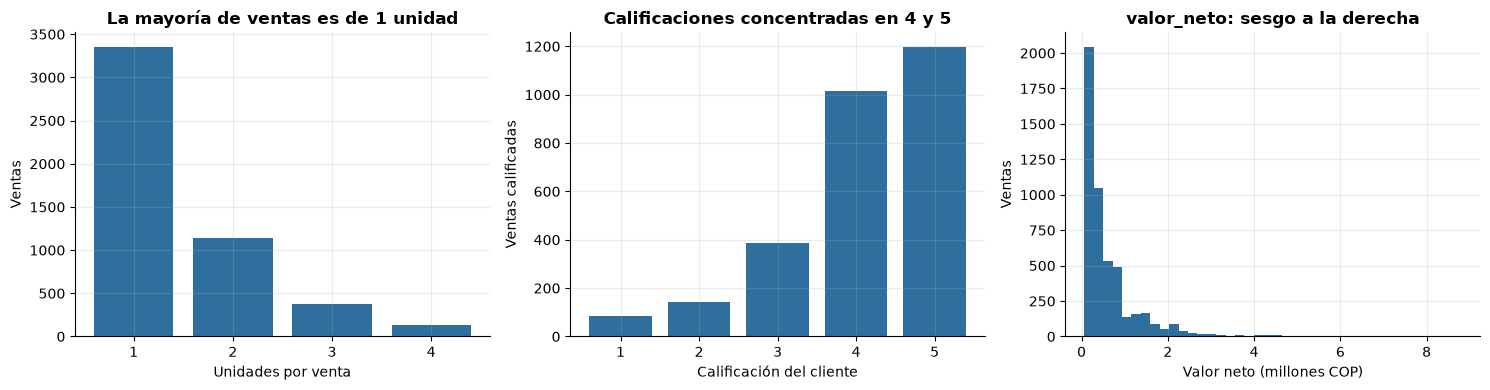

In [47]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

cantidad = df_ventas["cantidad"].value_counts().sort_index()
ejes[0].bar(cantidad.index.astype(str), cantidad.values, color=COLOR)
ejes[0].set(title="La mayoría de ventas es de 1 unidad", xlabel="Unidades por venta", ylabel="Ventas")

ejes[1].bar(calif.index.astype(int).astype(str), calif["frecuencia"], color=COLOR)
ejes[1].set(title="Calificaciones concentradas en 4 y 5", xlabel="Calificación del cliente", ylabel="Ventas calificadas")

ejes[2].hist(ventas_num["valor_neto"] / 1e6, bins=40, color=COLOR)
ejes[2].set(title="valor_neto: sesgo a la derecha", xlabel="Valor neto (millones COP)", ylabel="Ventas")
plt.tight_layout(); plt.show()

### Resúmenes para df_logistica

In [48]:
print("Número de eventos por estado_evento")
display(eda.frecuencias(df_logistica, "estado_evento").reindex(orden))
print("Número de eventos por ciudad_destino")
display(eda.frecuencias(df_logistica, "ciudad_destino"))

Número de eventos por estado_evento


,frecuencia,porcentaje
estado_evento,,
Pedido recibido,5000,10.00
Pago aprobado,4999,10.00
Orden enviada a logística,5004,10.01
En alistamiento,5001,10.00
Empacado,4998,10.00
Listo para despacho,5006,10.01
Despachado,5005,10.01
En tránsito,4998,10.00
En ruta de entrega,4991,9.98


Número de eventos por ciudad_destino


,frecuencia,porcentaje
ciudad_destino,,
Bogotá D.C.,16510,33.02
Cali,9412,18.82
Medellín,9186,18.37
Barranquilla,5331,10.66
Bucaramanga,5128,10.26
Pereira,4388,8.78
NaN,45,0.09


In [49]:
print("Frecuencia de las transportadoras (incluye nulos)")
display(eda.frecuencias(df_logistica, "transportadora"))
print("Frecuencia de transportadora por PEDIDO (primer valor no nulo de cada pedido)")
display(df_logistica.dropna(subset=["transportadora"]).groupby("pedido_id")["transportadora"].first().value_counts().to_frame("pedidos"))

Frecuencia de las transportadoras (incluye nulos)


,frecuencia,porcentaje
transportadora,,
NaN,30088,60.18
Envia,4216,8.43
Coordinadora,4097,8.19
Inter Rapidísimo,4008,8.02
TCC,3810,7.62
Servientrega,3781,7.56


Frecuencia de transportadora por PEDIDO (primer valor no nulo de cada pedido)


,pedidos
transportadora,
Envia,1059
Coordinadora,1027
Inter Rapidísimo,1007
TCC,957
Servientrega,950


In [50]:
print("Frecuencia de las incidencias (incluye nulos = sin incidencia)")
eda.frecuencias(df_logistica, "incidencia")

Frecuencia de las incidencias (incluye nulos = sin incidencia)


,frecuencia,porcentaje
incidencia,,
NaN,49489,98.98
Error de clasificación,98,0.20
Cliente ausente,91,0.18
Novedad climática,91,0.18
Retraso por tráfico,81,0.16
Paquete reprogramado,76,0.15
Dirección incompleta,74,0.15


In [51]:
print("Resumen estadístico de tiempo_etapa_horas y costo_envio")
display(pd.DataFrame({c: eda.estadisticos_numericos(df_logistica[c]) for c in ["tiempo_etapa_horas", "costo_envio"]}))

print("tiempo_etapa_horas por etapa (mediana y máximo)")
df_logistica.groupby("estado_evento")["tiempo_etapa_horas"].agg(["count", "median", "mean", "max"]).reindex(orden)

Resumen estadístico de tiempo_etapa_horas y costo_envio


,tiempo_etapa_horas,costo_envio
count,"45,000.00","50,000.00"
mean,4.00,"13,609.49"
std,3.46,"3,607.86"
min,0.08,"8,900.00"
p25,1.25,"9,900.00"
mediana,3.05,"13,900.00"
p75,5.89,"15,900.00"
max,24.69,"20,790.00"


tiempo_etapa_horas por etapa (mediana y máximo)


,count,median,mean,max
estado_evento,,,,
Pedido recibido,0,NaN,NaN,NaN
Pago aprobado,4999,0.34,0.36,1.15
Orden enviada a logística,5004,0.69,0.72,2.23
En alistamiento,5001,1.70,1.80,5.25
Empacado,4998,4.14,4.34,11.93
Listo para despacho,5006,2.76,2.89,8.22
Despachado,5005,2.74,2.89,8.44
En tránsito,4998,8.54,9.01,24.69
En ruta de entrega,4991,7.51,7.92,21.10


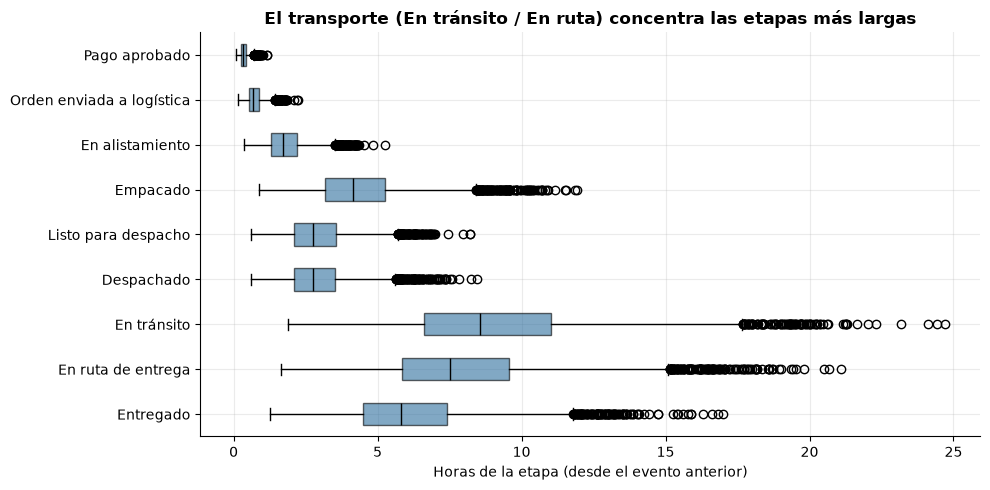

In [52]:
etapas_con_tiempo = [e for e in orden if e != "Pedido recibido"]
datos = [df_logistica.loc[df_logistica.estado_evento == e, "tiempo_etapa_horas"].dropna() for e in etapas_con_tiempo]
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(datos, orientation="horizontal", tick_labels=etapas_con_tiempo, patch_artist=True,
           boxprops=dict(facecolor=COLOR, alpha=0.6), medianprops=dict(color="black"))
ax.invert_yaxis()
ax.set(title="El transporte (En tránsito / En ruta) concentra las etapas más largas",
       xlabel="Horas de la etapa (desde el evento anterior)")
plt.tight_layout(); plt.show()

**Interpretación categórica:**
- **Bogotá D.C.** concentra alrededor de un tercio de las ventas y de los eventos. Le siguen Cali y Medellín. La distribución por ciudad es **coherente entre ambas fuentes**.
- **Página web** es el canal líder. **Tecnología** es la categoría con más ventas y **Tarjeta crédito** el medio de pago más usado.
- Aproximadamente **2 de cada 3 ventas son de 1 unidad**. Las calificaciones se concentran en 4 y 5, con un promedio cercano a 4,1.
- Los eventos por estado están balanceados (~5.000 cada uno), como se espera en un proceso secuencial. Las pequeñas diferencias (4.991 a 5.006) delatan **duplicados y etapas faltantes**.
- Las 5 transportadoras tienen una participación similar. Las incidencias son raras (~1 % de los eventos) y la más frecuente es *Error de clasificación*.

---
# PARTE 6. Preguntas de negocio

Se responden 10 preguntas con pandas sobre los **datos originales**. Para operar los montos se usa la vista numérica `ventas_num`, y para las fechas una conversión temporal.

> ⚠️ Como aún no se ha limpiado nada, las respuestas de logística incluyen el efecto de los duplicados. Esto muestra por qué la Parte 7 es necesaria.

In [53]:
# Copia de trabajo para las preguntas: df_ventas con montos numéricos (df_ventas sigue intacto)
vq = df_ventas.assign(**{c: ventas_num[c] for c in ["precio_unitario", "valor_bruto", "valor_descuento", "valor_neto"]})

# P1. ¿Qué ciudad genera mayores ventas netas y qué porcentaje del total representa?
p1 = vq.groupby("ciudad")["valor_neto"].sum().sort_values(ascending=False).to_frame("ventas_netas")
p1["participacion_%"] = p1["ventas_netas"] / p1["ventas_netas"].sum() * 100
p1

,ventas_netas,participacion_%
ciudad,,
Bogotá D.C.,"1,033,661,840.00",32.62
Cali,"616,180,785.00",19.45
Medellín,"587,603,785.00",18.55
Bucaramanga,"347,873,130.00",10.98
Barranquilla,"337,439,765.00",10.65
Pereira,"245,715,775.00",7.76


In [54]:
# P2. ¿Cuáles son los 5 productos más vendidos en unidades?
vq.groupby(["producto", "categoria"])["cantidad"].sum().nlargest(5).to_frame("unidades")

,,unidades
producto,categoria,
Monitor 24 pulgadas,Tecnología,349
Audífonos Bluetooth,Tecnología,344
Mouse inalámbrico,Tecnología,344
Smartwatch,Tecnología,334
Teclado mecánico,Tecnología,334


In [55]:
# P3. ¿Qué canal tiene el ticket promedio (valor_neto por venta) más alto?
vq.groupby("canal")["valor_neto"].agg(ventas="count", ticket_promedio="mean", ticket_mediano="median").sort_values("ticket_promedio", ascending=False)

,ventas,ticket_promedio,ticket_mediano
canal,,,
Tienda física,1499,"637,273.13","363,120.00"
Página web,2020,"637,090.10","382,712.50"
Aplicación móvil,1481,"625,442.71","349,900.00"


In [56]:
# P4. ¿Cuál es el medio de pago preferido en cada canal?
tabla = pd.crosstab(vq["canal"], vq["medio_pago"], normalize="index") * 100
display(tabla.round(1))
tabla.idxmax(axis=1).to_frame("medio_pago_preferido")

medio_pago,Billetera digital,Efectivo,PSE,Tarjeta crédito,Tarjeta débito,Transferencia
canal,,,,,,
Aplicación móvil,15.50,0.00,29.20,37.30,18.00,0.00
Página web,0.00,0.00,32.50,41.20,19.10,7.20
Tienda física,0.00,28.10,9.20,33.50,29.20,0.00


,medio_pago_preferido
canal,
Aplicación móvil,Tarjeta crédito
Página web,Tarjeta crédito
Tienda física,Tarjeta crédito


,ventas,ventas_netas
fecha_venta,,
2026-01,830,"533,719,660.00"
2026-02,764,"441,439,530.00"
2026-03,867,"536,555,540.00"
2026-04,851,"543,987,720.00"
2026-05,821,"524,728,000.00"
2026-06,867,"588,044,630.00"


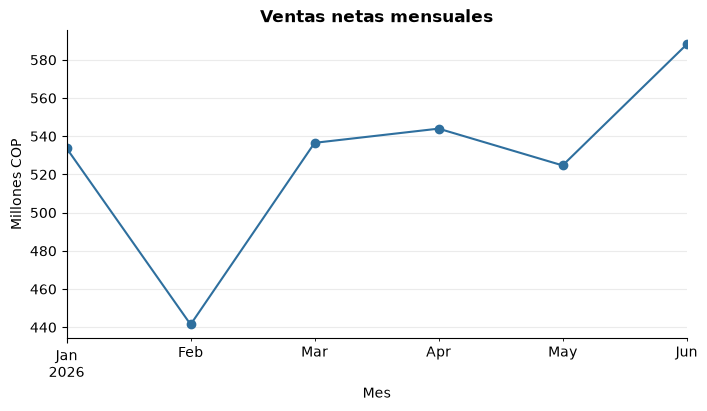

In [57]:
# P5. ¿Cómo evolucionan las ventas netas mes a mes?
p5 = vq.groupby(vq["fecha_venta"].dt.to_period("M")).agg(ventas=("id_venta", "count"), ventas_netas=("valor_neto", "sum"))
display(p5)
ax = (p5["ventas_netas"] / 1e6).plot(marker="o", color=COLOR, title="Ventas netas mensuales")
ax.set(xlabel="Mes", ylabel="Millones COP"); plt.show()

In [58]:
# P6. ¿Qué categoría concentra el mayor valor descontado y cuál es su descuento promedio?
vq.groupby("categoria").agg(valor_descontado=("valor_descuento", "sum"),
                            descuento_pct_promedio=("descuento_pct", lambda s: pd.to_numeric(s).mean()),
                            ventas_con_descuento=("valor_descuento", lambda s: (s > 0).sum())
                            ).sort_values("valor_descontado", ascending=False)

,valor_descontado,descuento_pct_promedio,ventas_con_descuento
categoria,,,
Deportes,"47,326,885.00",5.01,406
Tecnología,"42,520,925.00",5.36,712
Oficina,"34,869,525.00",5.40,406
Electrodomésticos,"24,267,240.00",5.34,568
Hogar,"23,980,945.00",5.21,473


In [59]:
# P7. ¿Qué tan recurrentes son los clientes? ¿Quiénes son los 5 que más compran?
compras = vq.groupby("id_cliente").agg(compras=("id_venta", "count"), valor_neto=("valor_neto", "sum"))
print(f"Clientes distintos: {len(compras):,} | con más de una compra: {(compras.compras > 1).mean() * 100:.1f}%")
compras.nlargest(5, "valor_neto")

Clientes distintos: 2,292 | con más de una compra: 63.6%


,compras,valor_neto
id_cliente,,
CLI00809,4,"15,078,470.00"
CLI01676,5,"10,264,650.00"
CLI02103,4,"10,179,100.00"
CLI01401,5,"9,597,100.00"
CLI00741,2,"9,513,500.00"


In [60]:
# P8. ¿Qué calificación promedio recibe cada categoría (solo ventas calificadas)?
vq.dropna(subset=["calificacion_cliente"]).groupby("categoria")["calificacion_cliente"].agg(
    calificaciones="count", promedio="mean", pct_4_o_5=lambda s: (s >= 4).mean() * 100).sort_values("promedio", ascending=False)

,calificaciones,promedio,pct_4_o_5
categoria,,,
Oficina,421,4.18,81.47
Tecnología,785,4.11,78.73
Hogar,527,4.10,77.61
Electrodomésticos,632,4.09,78.01
Deportes,463,3.99,75.59


In [61]:
# P9. ¿Qué etapa logística tarda más (mediana de horas)?
df_logistica.groupby("estado_evento")["tiempo_etapa_horas"].median().dropna().sort_values(ascending=False).to_frame("mediana_horas")

,mediana_horas
estado_evento,
En tránsito,8.54
En ruta de entrega,7.51
Entregado,5.83
Empacado,4.14
Listo para despacho,2.76
Despachado,2.74
En alistamiento,1.70
Orden enviada a logística,0.69
Pago aprobado,0.34


In [62]:
# P10. ¿Qué porcentaje de pedidos se entregó DESPUÉS de la fecha prometida, por ciudad?
entregas = df_logistica[df_logistica["estado_evento"] == "Entregado"].copy()
entregas["tarde"] = pd.to_datetime(entregas["fecha_evento"]) > pd.to_datetime(entregas["fecha_prometida_entrega"])
print(f"Entregas tardías (global): {entregas['tarde'].mean() * 100:.1f}% de {len(entregas):,} eventos 'Entregado'")
entregas.groupby("ciudad_destino")["tarde"].agg(entregas="count", pct_tarde=lambda s: s.mean() * 100).sort_values("pct_tarde", ascending=False)

Entregas tardías (global): 17.1% de 4,998 eventos 'Entregado'


,entregas,pct_tarde
ciudad_destino,,
Cali,939,19.17
Medellín,920,18.04
Bogotá D.C.,1650,16.48
Barranquilla,534,16.29
Bucaramanga,512,16.21
Pereira,438,15.07


**Resumen a 10 preguntas de negocio** :
- **P1–P3:** Bogotá lidera en ventas netas, en línea con su volumen de ventas. El ticket promedio es similar entre canales; la diferencia real entre canales está en **cómo pagan** los clientes (P4): *Efectivo* solo aparece en tienda física, *Billetera digital* solo en la app y *Transferencia* solo en la web. Esto es coherente con el negocio.
- **P5:** las ventas son estables en el semestre (enero–junio 2026): entre 764 y 867 ventas por mes. Febrero es el mes más bajo (tiene menos días) y junio el más alto en valor neto.
- **P6:** Deportes y Tecnología concentran el mayor valor descontado, porque tienen productos de precio alto.
- **P7:** la mayoría de clientes repite compra, lo que hace útil un análisis por cliente.
- **P9–P10:** las etapas de transporte son las más lentas, y una parte relevante de las entregas llega después de lo prometido. Este es un KPI clave que se consolida en Gold.

---
# PARTE 7. Proceso de transformación de datos (Medallion)

```
      EXTRACCIÓN              BRONZE (crudo)            SILVER (limpio)                 GOLD (integrado)
  MySQL.ventas     ──►  ventas_bronze.csv     ──►  ventas_silver.csv        ─┐
                                                                             ├─► gold_pedidos + KPIs (CSV + SQLite)
  Excel logística  ──►  logistica_bronze.csv  ──►  logistica_silver.csv     ─┘
```

- **Bronze:** se guarda `df_ventas` y `df_logistica` **sin ningún cambio**. Si una regla de limpieza resulta equivocada, se puede volver a procesar desde aquí sin volver a consultar las fuentes.
- **Silver:** limpieza **por fuente** (duplicados, tipos, estandarización, nulos). Código en `src/transform/clean_database.py` (ventas) y `src/transform/clean_excel.py` (logística).
- **Gold:** integración por `pedido_id` y KPIs, en `src/transform/gold_transformations.py`.

## 7.1 Capa Bronze

In [67]:
from src.load.load_files import guardar_csv

rutas = {capa: ruta_absoluta(config["rutas"][capa]) for capa in ("bronze", "silver", "gold")}
guardar_csv(df_ventas, rutas["bronze"], "ventas_bronze.csv")
guardar_csv(df_logistica, rutas["bronze"], "logistica_bronze.csv")

# Huella de los originales para verificar al final que la limpieza NO los modificó
huella_ventas = pd.util.hash_pandas_object(df_ventas).sum()
huella_logistica = pd.util.hash_pandas_object(df_logistica).sum()
print("Bronze guardado:", sorted(p.name for p in rutas["bronze"].glob("*.csv")))

Bronze guardado: ['logistica_bronze.csv', 'ventas_bronze.csv']


## 7.2 Capa Silver — decisiones de limpieza

Cada decisión responde a un problema **cuantificado en el EDA** y se toma según **el significado de la variable**

### df_ventas → df_ventas_transformado

| # | Problema (EDA) | Decisión | Por qué |
|---|---|---|---|
| 1 | Duplicados: 0 | Regla `drop_duplicates()` por fila, `id_venta` y `pedido_id` | Hoy no hay duplicados, pero el pipeline se ejecuta periódicamente; la regla protege las cargas futuras. |
| 2 | Montos `Decimal` (object) | Convertir a `float64` redondeado a 2 decimales | Permite cálculos y `describe()`. |
| 3 | `calificacion_cliente` float | `Int64` (entero que admite nulos) | Es una escala entera 1–5. |
| 4 | Texto categórico | `strip()` + MAYÚSCULAS, conservando tildes | Evita variantes como "Cali" y "cali ". Las tildes se conservan porque son parte del dato y ambas fuentes las escriben igual (la unión no se afecta). |
| 5 | `id_tienda` nula (70 %) | Canal digital → **"NO APLICA"**; tienda física sin tienda → "NO INFORMADO" | No se usa la moda: asignaría una tienda falsa a ventas web y distorsionaría las ventas por tienda. El nulo significa "no aplica", no "desconocido". |
| 6 | `calificacion_cliente` nula (43 %) | **Mantener el nulo** + bandera `tiene_calificacion` | El nulo tiene interpretación válida (no calificó). Imputar con media o moda (≈4–5) **inventaría satisfacción** y sesgaría el indicador. |
| 7 | Coherencia de montos | Validar las 3 reglas aritméticas | Se documenta el resultado. |
| 8 | Análisis temporal | Crear `mes_venta` | Facilita los agregados mensuales. |

### df_logistica → df_logisitica_transformado

| # | Problema (EDA) | Decisión | Por qué |
|---|---|---|---|
| 1 | 99 filas duplicadas | `drop_duplicates()` | Son copias exactas; eliminarlas no pierde información. |
| 2 | `evento_id` 35782 repetido con datos distintos | Conservar la fila **con menos nulos** | Es la versión más completa del mismo evento. |
| 3 | Fechas como texto | `to_datetime` con formato explícito `%Y-%m-%d %H:%M:%S` | El formato explícito detecta valores inválidos (quedan `NaT` y se cuentan). |
| 4 | Texto categórico | MAYÚSCULAS + `strip()` y `orden_etapa` (1–10) | Estandariza y permite ordenar las etapas. |
| 5 | `centro_logistico`, `ciudad_destino`, `fecha_prometida_entrega` nulos | **Copiar el valor de otro evento del mismo pedido** | El EDA mostró que son constantes por pedido. Es una recuperación exacta, mejor que la moda global (que podría asignar Bogotá a un pedido de Cali). |
| 6 | `transportadora`/`numero_guia` nulos **antes** del despacho | transportadora = **"NO APLICA"**; numero_guia **se mantiene nulo** | Es un nulo normal del proceso. No se inventa un número de guía que todavía no existe. |
| 7 | `transportadora`/`numero_guia` nulos **después** del despacho | Copiar del mismo pedido (etapas post-despacho) | Cada pedido tiene una única transportadora y guía. |
| 8 | `fecha_evento` nula | **Reconstruir:** fecha anterior + `tiempo_etapa_horas` (o fecha siguiente − tiempo del siguiente) + bandera `fecha_evento_imputada` | El EDA probó que `tiempo_etapa_horas` es el tiempo desde el evento anterior. Es una regla determinística, no un promedio. |
| 9 | `tiempo_etapa_horas` nulo en "Pedido recibido" | **Mantener el nulo** | No hay etapa previa. Imputar 0 o la media alteraría los promedios de duración. |
| 10 | `incidencia` / `observacion` nulas | "SIN INCIDENCIA" / "Sin observación" + bandera `tiene_incidencia` | El nulo significa "no hubo novedad". Queda como categoría explícita para contar. |
| 11 | Pedidos con etapas faltantes | **Solo documentar** | No se crean eventos que no ocurrieron. En Gold se marcan con `pedido_completo`. |

**¿Por qué no se usaron media ni mediana?** En estas fuentes **ningún nulo numérico corresponde a un dato perdido al azar**. Los nulos de `tiempo_etapa_horas` son estructurales, y `fecha_evento` se puede reconstruir exactamente. Imputar con media o mediana habría inventado valores cuando existía una regla del negocio más precisa. Si en una carga futura faltaran duraciones en otras etapas, el código las recalcula con la diferencia de fechas. La mediana sería la alternativa preferida frente a la media, porque el EDA mostró asimetría y atípicos.

In [63]:
from src.transform.clean_database import limpiar_ventas
from src.transform.clean_excel import limpiar_logistica

df_ventas_transformado, bitacora_ventas = limpiar_ventas(df_ventas)
df_logisitica_transformado, bitacora_logistica = limpiar_logistica(df_logistica)

bitacora = pd.concat([bitacora_ventas, bitacora_logistica], ignore_index=True)
with pd.option_context("display.max_colwidth", 130):
    display(bitacora)   # registro de cada decisión y cuántas filas afectó

,fuente,paso,decision,filas_afectadas
0,ventas,Duplicados,Eliminar filas completamente duplicadas,0
1,ventas,Duplicados,Conservar un solo registro por id_venta,0
2,ventas,Duplicados,Conservar un solo registro por pedido_id,0
3,ventas,Tipos de datos,Monetarias y descuento_pct de Decimal(object) a float; cantidad y calificacion_cliente a Int64; fecha_venta a datetime,5000
4,ventas,Estandarización,"Texto en MAYÚSCULAS y sin espacios extra en ['ciudad', 'canal', 'categoria', 'producto', 'medio_pago', 'pedido_id', 'id_client...",5000
5,ventas,Nulos id_tienda,Canal digital sin tienda -> 'NO APLICA',3501
6,ventas,Nulos id_tienda,Tienda física sin id_tienda -> 'NO INFORMADO',0
7,ventas,Nulos calificacion_cliente,Se mantiene el nulo (cliente no calificó) y se crea 'tiene_calificacion',2172
8,ventas,Validación,Registros que incumplen: valor_bruto = cantidad x precio_unitario,0
9,ventas,Validación,Registros que incumplen: valor_descuento = valor_bruto x descuento_pct / 100,0


**¿Qué tan confiable es la reconstrucción de `fecha_evento`?** Se valida con un experimento: se toman 500 eventos cuya fecha **sí se conoce**, se borra su fecha en una copia, se aplica la misma limpieza y se compara la fecha reconstruida con la real.

In [64]:
prueba = df_logistica.drop_duplicates().copy()
muestra = prueba[prueba["fecha_evento"].notna()].sample(500, random_state=42)
prueba.loc[muestra.index, "fecha_evento"] = None              # se "borran" fechas conocidas

reconstruida, _ = limpiar_logistica(prueba)
reconstruida = reconstruida.set_index("evento_id").loc[muestra["evento_id"], "fecha_evento"]
error_seg = (reconstruida.values - pd.to_datetime(muestra["fecha_evento"]).values) / pd.Timedelta(seconds=1)
error_seg = pd.Series(abs(error_seg))

print(f"Fechas reconstruidas: {error_seg.notna().sum()} de {len(error_seg)}")
print(f"Reconstruidas con error <= 60 segundos: {(error_seg <= 60).mean() * 100:.1f}%")
print(f"Error mediano: {error_seg.median():.0f} s | error máximo: {error_seg.max() / 3600:.1f} h")

Fechas reconstruidas: 498 de 500
Reconstruidas con error <= 60 segundos: 99.4%
Error mediano: 9 s | error máximo: 2.9 h


La gran mayoría de fechas se recupera prácticamente exacta; el error de segundos viene del redondeo de `tiempo_etapa_horas` a 2 decimales. Los pocos casos con error grande corresponden a pedidos con una **etapa faltante**, donde el "evento anterior" registrado no es el real. Por eso la bandera `fecha_evento_imputada` permite excluir estas fechas de un análisis fino.

In [65]:
# (continuación) La bitácora completa también se guarda en data/silver/bitacora_limpieza.csv
print(f"Decisiones registradas: {len(bitacora)}")

Decisiones registradas: 36


In [68]:
# Verificación: Bronze (los DataFrames originales) quedó intacto
print("df_ventas sin cambios   :", pd.util.hash_pandas_object(df_ventas).sum() == huella_ventas, df_ventas.shape)
print("df_logistica sin cambios:", pd.util.hash_pandas_object(df_logistica).sum() == huella_logistica, df_logistica.shape)
print("df_ventas_transformado     :", df_ventas_transformado.shape)
print("df_logisitica_transformado :", df_logisitica_transformado.shape)

df_ventas sin cambios   : True (5000, 17)
df_logistica sin cambios: True (50000, 13)
df_ventas_transformado     : (5000, 19)
df_logisitica_transformado : (49900, 16)


In [70]:
# Nulos ANTES vs DESPUÉS de la limpieza
def comparar_nulos(antes, despues):
    tabla = pd.DataFrame({"nulos_antes": antes.isna().sum(), "nulos_despues": despues.isna().sum()}).fillna(0).astype(int)
    return tabla[(tabla.nulos_antes > 0) | (tabla.nulos_despues > 0)]

print("Ventas"); display(comparar_nulos(df_ventas, df_ventas_transformado))
print("Logística"); display(comparar_nulos(df_logistica, df_logisitica_transformado))

Ventas


,nulos_antes,nulos_despues
calificacion_cliente,2172,2172
id_tienda,3501,0


Logística


,nulos_antes,nulos_despues
centro_logistico,90,0
ciudad_destino,45,0
fecha_evento,65,0
fecha_prometida_entrega,55,0
incidencia,49489,0
numero_guia,30068,29944
observacion,48277,0
tiempo_etapa_horas,5000,4991
transportadora,30088,0


Los nulos que **quedan** son intencionales:
- `calificacion_cliente`: el cliente no calificó.
- `numero_guia`: etapas anteriores al despacho, cuando aún no hay guía.
- `tiempo_etapa_horas`: solo "Pedido recibido".

In [71]:
print("Tipos en df_ventas_transformado:")
print(df_ventas_transformado.dtypes.to_string())
print("\nTipos en df_logisitica_transformado:")
print(df_logisitica_transformado.dtypes.to_string())

Tipos en df_ventas_transformado:
id_venta                         int64
pedido_id                          str
fecha_venta             datetime64[us]
id_cliente                         str
ciudad                             str
canal                              str
id_tienda                          str
categoria                          str
producto                           str
cantidad                         Int64
precio_unitario                float64
descuento_pct                  float64
valor_bruto                    float64
valor_descuento                float64
valor_neto                     float64
medio_pago                         str
calificacion_cliente             Int64
tiene_calificacion                bool
mes_venta                          str

Tipos en df_logisitica_transformado:
evento_id                           int64
pedido_id                             str
fecha_evento               datetime64[us]
estado_evento                         str
centro_logistico    

In [72]:
# Categorías estandarizadas (ejemplo)
for col in ["canal", "id_tienda"]:
    print(df_ventas_transformado[col].value_counts().head(4).to_string(), "\n")
print(df_logisitica_transformado["transportadora"].value_counts().to_string())

canal
PÁGINA WEB          2020
TIENDA FÍSICA       1499
APLICACIÓN MÓVIL    1481 

id_tienda
NO APLICA    3501
BOG-01        175
BAQ-01        174
BOG-02        173 

transportadora
NO APLICA           29944
ENVIA                4230
COORDINADORA         4097
INTER RAPIDÍSIMO     4014
TCC                  3821
SERVIENTREGA         3794


In [73]:
# Duplicados después de la limpieza
print("Ventas    -> filas duplicadas:", df_ventas_transformado.duplicated().sum(),
      "| id_venta repetidos:", df_ventas_transformado.id_venta.duplicated().sum())
print("Logística -> filas duplicadas:", df_logisitica_transformado.duplicated().sum(),
      "| evento_id repetidos:", df_logisitica_transformado.evento_id.duplicated().sum())
print("Eventos por estado después de limpiar:")
df_logisitica_transformado["estado_evento"].value_counts()

Ventas    -> filas duplicadas: 0 | id_venta repetidos: 0
Logística -> filas duplicadas: 0 | evento_id repetidos: 0
Eventos por estado después de limpiar:


estado_evento
DESPACHADO                   4996
LISTO PARA DESPACHO          4995
PEDIDO RECIBIDO              4991
PAGO APROBADO                4990
EN ALISTAMIENTO              4990
EMPACADO                     4990
ENTREGADO                    4990
ORDEN ENVIADA A LOGÍSTICA    4988
EN TRÁNSITO                  4988
EN RUTA DE ENTREGA           4982
Name: count, dtype: int64

In [74]:
# Guardar Silver (datos limpios + bitácora de decisiones)
guardar_csv(df_ventas_transformado, rutas["silver"], "ventas_silver.csv")
guardar_csv(df_logisitica_transformado, rutas["silver"], "logistica_silver.csv")
guardar_csv(bitacora, rutas["silver"], "bitacora_limpieza.csv")
print("Silver guardado:", sorted(p.name for p in rutas["silver"].glob("*.csv")))

Silver guardado: ['bitacora_limpieza.csv', 'logistica_silver.csv', 'ventas_silver.csv']


## 7.3 Capa Gold — integración para análisis

**Problema de granularidad:** ventas tiene 1 fila por pedido y logística ~10 filas por pedido. Un `merge` directo **multiplicaría cada venta por 10** y las ventas netas quedarían infladas.

**Solución:**
1. **Resumir la logística a 1 fila por pedido**: centro, transportadora, guía, costo de envío, fechas de hitos (recibido, despachado, entregado), número de incidencias, estado actual y si el pedido está completo.
2. Calcular métricas de desempeño: `horas_hasta_despacho`, `horas_totales_entrega`, `horas_vs_promesa` (positivo = retraso) y `entrega_a_tiempo`.
3. Unir con ventas por `pedido_id` usando `validate="one_to_one"`. Pandas lanza un error si la relación no es 1 a 1, así que la unión no puede duplicar ventas en silencio.
4. Construir tablas de KPIs por ciudad, transportadora y categoría.

In [75]:
from src.transform.gold_transformations import construir_gold
from src.load.load_database import cargar_sqlite

tablas_gold = construir_gold(df_ventas_transformado, df_logisitica_transformado)
gold_pedidos = tablas_gold["gold_pedidos"]

print("gold_pedidos:", gold_pedidos.shape, "| pedidos únicos:", gold_pedidos.pedido_id.is_unique)
print("¿Todas las ventas tienen logística?:", gold_pedidos.tiene_logistica.all())
print("¿ciudad (ventas) = ciudad_destino (logística)?:", gold_pedidos.ciudad_consistente.mean() * 100, "%")
gold_pedidos.head(3).T

gold_pedidos: (5000, 42) | pedidos únicos: True
¿Todas las ventas tienen logística?: True
¿ciudad (ventas) = ciudad_destino (logística)?: 100.0 %


,0,1,2
id_venta,1,2,3
pedido_id,PED000001,PED000002,PED000003
fecha_venta,2026-01-18 22:06:15,2026-04-25 21:07:01,2026-03-28 02:39:43
id_cliente,CLI00011,CLI00802,CLI00255
ciudad,BOGOTÁ D.C.,CALI,MEDELLÍN
canal,APLICACIÓN MÓVIL,PÁGINA WEB,PÁGINA WEB
id_tienda,NO APLICA,NO APLICA,NO APLICA
categoria,DEPORTES,DEPORTES,TECNOLOGÍA
producto,BANDA CAMINADORA,MANCUERNAS AJUSTABLES,TABLET 10 PULGADAS
cantidad,1,1,1


In [76]:
# Validación clave: la integración NO infló las ventas
print(f"Ventas netas Silver: {df_ventas_transformado.valor_neto.sum():,.0f}")
print(f"Ventas netas Gold  : {gold_pedidos.valor_neto.sum():,.0f}")

print("\nEstado actual de los pedidos:"); display(gold_pedidos.estado_actual.value_counts().to_frame())
print("Entrega a tiempo (NA = aún no entregado):")
gold_pedidos.entrega_a_tiempo.value_counts(dropna=False).to_frame()

Ventas netas Silver: 3,168,475,080
Ventas netas Gold  : 3,168,475,080

Estado actual de los pedidos:


,count
estado_actual,
ENTREGADO,4990
EN RUTA DE ENTREGA,10


Entrega a tiempo (NA = aún no entregado):


,count
entrega_a_tiempo,
True,4135
False,855
<NA>,10


In [77]:
print("KPIs por ciudad"); display(tablas_gold["gold_kpi_ciudad"])
print("KPIs por transportadora"); display(tablas_gold["gold_kpi_transportadora"])
print("KPIs por categoría"); display(tablas_gold["gold_kpi_categoria"])

KPIs por ciudad


,ciudad,pedidos,ventas_netas,ticket_promedio,costo_envio_promedio,horas_promedio_entrega,pct_entrega_a_tiempo,incidencias,calificacion_promedio,incidencias_por_100_pedidos
0,BOGOTÁ D.C.,1653,"1,033,661,840.00","625,324.77","13,667.08",29.34,83.43,152,4.09,9.20
1,CALI,942,"616,180,785.00","654,119.73","13,772.76",38.19,80.83,101,4.08,10.72
2,MEDELLÍN,919,"587,603,785.00","639,394.76","13,484.89",35.62,81.94,114,4.11,12.40
3,BARRANQUILLA,534,"337,439,765.00","631,909.67","13,439.81",46.53,83.71,51,4.08,9.55
4,BUCARAMANGA,513,"347,873,130.00","678,115.26","13,476.67",41.22,83.82,47,4.14,9.16
5,PEREIRA,439,"245,715,775.00","559,717.03","13,680.66",38.76,84.90,46,4.08,10.48


KPIs por transportadora


,transportadora,pedidos,ventas_netas,ticket_promedio,costo_envio_promedio,horas_promedio_entrega,pct_entrega_a_tiempo,incidencias,calificacion_promedio,incidencias_por_100_pedidos
0,ENVIA,1059,"681,299,760.00","643,342.55","13,509.45",35.96,83.54,111,4.12,10.48
1,COORDINADORA,1027,"636,657,380.00","619,919.55","13,701.31",35.98,83.04,100,4.13,9.74
2,INTER RAPIDÍSIMO,1007,"652,745,345.00","648,207.89","13,721.29",36.53,82.53,103,4.10,10.23
3,TCC,957,"577,705,020.00","603,662.51","13,588.90",35.92,82.13,100,4.08,10.45
4,SERVIENTREGA,950,"620,067,575.00","652,702.71","13,531.32",35.87,83.02,97,4.03,10.21


KPIs por categoría


,categoria,pedidos,ventas_netas,ticket_promedio,costo_envio_promedio,horas_promedio_entrega,pct_entrega_a_tiempo,incidencias,calificacion_promedio,incidencias_por_100_pedidos
0,TECNOLOGÍA,1366,"764,924,075.00","559,973.70","13,547.87",36.48,81.88,148,4.11,10.83
1,ELECTRODOMÉSTICOS,1104,"442,194,260.00","400,538.28","13,766.83",35.42,84.11,108,4.09,9.78
2,HOGAR,935,"464,110,855.00","496,375.25","13,669.70",36.37,82.21,88,4.10,9.41
3,DEPORTES,812,"863,788,915.00","1,063,779.45","13,482.92",35.98,83.33,81,3.99,9.98
4,OFICINA,783,"633,456,975.00","809,012.74","13,563.42",35.90,83.14,86,4.18,10.98


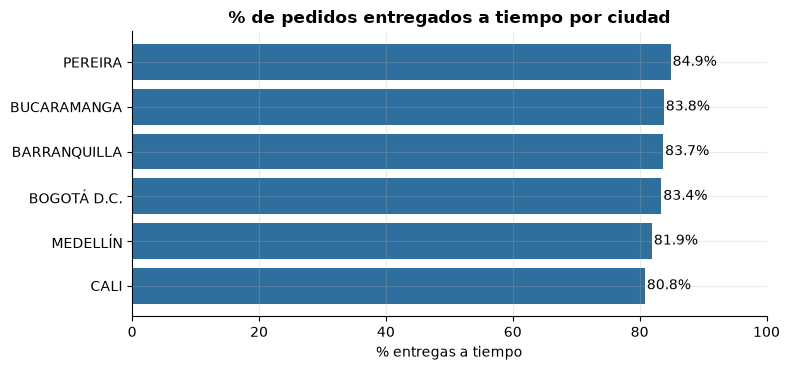

In [78]:
kpi = tablas_gold["gold_kpi_ciudad"].sort_values("pct_entrega_a_tiempo")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(kpi["ciudad"], kpi["pct_entrega_a_tiempo"], color=COLOR)
for y, valor in enumerate(kpi["pct_entrega_a_tiempo"]):
    ax.text(valor + 0.3, y, f"{valor:.1f}%", va="center")
ax.set(title="% de pedidos entregados a tiempo por ciudad", xlabel="% entregas a tiempo", xlim=(0, 100))
plt.tight_layout(); plt.show()

In [75]:
# Guardar Gold en CSV y en SQLite (consultable con SQL)
for nombre, tabla in tablas_gold.items():
    guardar_csv(tabla, rutas["gold"], f"{nombre}.csv")
ruta_db = ruta_absoluta(config["gold"]["base_datos_sqlite"])
cargar_sqlite(tablas_gold, ruta_db)

# Ejemplo de consulta SQL sobre la capa Gold
import sqlite3
with sqlite3.connect(ruta_db) as con:
    display(pd.read_sql('''
        SELECT transportadora, COUNT(*) AS pedidos,
               ROUND(AVG(horas_totales_entrega), 2) AS horas_promedio,
               SUM(incidencias) AS incidencias
        FROM gold_pedidos GROUP BY transportadora ORDER BY pedidos DESC''', con))

,transportadora,pedidos,horas_promedio,incidencias
0,ENVIA,1059,35.96,111
1,COORDINADORA,1027,35.98,100
2,INTER RAPIDÍSIMO,1007,36.53,103
3,TCC,957,35.92,100
4,SERVIENTREGA,950,35.87,97


---
# PARTE 8. Automatización del pipeline (orquestador con `schedule`)

Todo lo anterior está empaquetado en `src/pipeline.py → ejecutar_pipeline()`. Esa función hace **Extracción → Bronze → Silver → Gold** y deja un log en `logs/etl.log`. El orquestador está en `main.py`:

```bash
python main.py              # ejecuta el pipeline una vez
python main.py --programar  # orquestador: lo ejecuta cada N minutos (config.yaml -> orquestador.intervalo_minutos)
```

**Cómo funciona `schedule`:**
1. `schedule.every(N).minutes.do(tarea)` **registra** una tarea y su frecuencia. Para producción se podría usar `schedule.every().day.at("06:00")`.
2. Un ciclo `while True` llama a `schedule.run_pending()` cada segundo; esa llamada ejecuta las tareas cuya hora ya llegó.
3. La tarea está envuelta en `try/except`: si una ejecución falla (por ejemplo, la BD no responde), el error queda en el log y el orquestador **sigue vivo** para el siguiente intento.


In [76]:
import inspect
import main
print(inspect.getsource(main.tarea_etl))
print(inspect.getsource(main.iniciar_orquestador))

def tarea_etl(config: dict) -> None:
    """Envuelve el pipeline para que un error no detenga al orquestador.

    Si una ejecución falla (p. ej. la BD no responde), se registra el error y
    el orquestador sigue vivo para intentarlo en la siguiente programación.
    """
    try:
        ejecutar_pipeline(config)
    except Exception:
        logger.exception("La ejecución del pipeline falló; se reintentará en la próxima programación")

def iniciar_orquestador(config: dict) -> None:
    """PARTE 8: programa el pipeline cada N minutos con la librería schedule."""
    parametros = config["orquestador"]
    minutos = parametros["intervalo_minutos"]

    schedule.every(minutos).minutes.do(tarea_etl, config=config)
    # Alternativa para producción: schedule.every().day.at("06:00").do(tarea_etl, config=config)
    logger.info("Orquestador iniciado: pipeline cada %s minuto(s). Ctrl+C para detener.", minutos)

    if parametros.get("ejecutar_al_iniciar", True):
        schedule.run_all()  # 

In [77]:
# Demostración controlada (sin ciclo infinito): se registra la tarea, se ejecuta una vez y se limpia
import schedule
from src.logger import configurar_logging

configurar_logging(ruta_absoluta(config["rutas"]["log"]))
schedule.clear()
schedule.every(config["orquestador"]["intervalo_minutos"]).minutes.do(main.tarea_etl, config=config)
tarea = schedule.get_jobs()[0]
print(f"Tarea programada: {tarea.job_func.func.__name__} cada {tarea.interval} {tarea.unit}")

schedule.run_all()          # fuerza una ejecución inmediata del pipeline completo
print("Próxima ejecución programada:", schedule.next_run())
schedule.clear()

2026-09-28 20:13:26,660 | INFO | src.pipeline | ===== Inicio del pipeline ETL =====


Tarea programada: tarea_etl cada 60 minutes


2026-09-28 20:13:29,801 | INFO | src.extract.extract_database | Extracción MySQL: tabla 'ventas' -> 5000 filas x 17 columnas


2026-09-28 20:13:36,027 | INFO | src.extract.extract_excel | Extracción Excel: 'kaismart_eventos_logisticos.xlsx' -> 50000 filas x 13 columnas


2026-09-28 20:13:36,063 | INFO | src.load.load_files | Guardado bronze/ventas_bronze.csv (5000 filas)


...

2026-09-28 20:13:37,971 | INFO | src.load.load_database | SQLite: tabla 'gold_kpi_ciudad' cargada (6 filas)


2026-09-28 20:13:37,988 | INFO | src.load.load_database | SQLite: tabla 'gold_kpi_transportadora' cargada (5 filas)


2026-09-28 20:13:38,005 | INFO | src.load.load_database | SQLite: tabla 'gold_kpi_categoria' cargada (5 filas)


2026-09-28 20:13:38,006 | INFO | src.pipeline | ===== Pipeline finalizado en 11.3 s =====


Próxima ejecución programada: 2026-09-28 21:13:38.030671


In [78]:
# Evidencia: archivos generados por el pipeline en cada capa
for capa, ruta in rutas.items():
    print(f"{capa.upper():7s}", sorted(p.name for p in ruta.iterdir() if p.is_file()))

BRONZE  ['logistica_bronze.csv', 'ventas_bronze.csv']
SILVER  ['bitacora_limpieza.csv', 'logistica_silver.csv', 'ventas_silver.csv']
GOLD    ['gold_kpi_categoria.csv', 'gold_kpi_ciudad.csv', 'gold_kpi_transportadora.csv', 'gold_pedidos.csv', 'kaismart_gold.db']


---
# CONCLUSIONES

> Las cifras provienen de las salidas de este notebook, ejecutado sobre los datos reales (MySQL `clientes.ventas` y `kaismart_eventos_logisticos.xlsx`).

### Hallazgos sobre `df_ventas`
1. **Estructura sólida:** 5.000 ventas × 17 variables, del 01-ene al 30-jun-2026 (180 días). Una fila = una venta = un pedido. `id_venta` y `pedido_id` son 100 % únicos y no hay filas duplicadas; las restricciones PK/UNI de MySQL lo garantizan.
2. **Tipos incoherentes en montos:** las 5 variables monetarias y porcentuales (`precio_unitario`, `descuento_pct`, `valor_bruto`, `valor_descuento`, `valor_neto`) llegan como `Decimal` (dtype `object`) y deben convertirse a numéricas. Aun así, sus valores son **confiables**: las 3 reglas aritméticas se cumplen en el 100 % de los registros.
3. **Solo 2 variables tienen nulos, y ambos tienen explicación:** `id_tienda` (70,02 %, 3.501) coincide exactamente con las ventas web y app (nulo estructural). `calificacion_cliente` (43,44 %, 2.172) son clientes que no calificaron, así que cualquier indicador de satisfacción se basa solo en 2.828 ventas (56,6 %).
4. **Distribuciones asimétricas:** `valor_neto` tiene media de 633.695 y mediana de 367.110 (asimetría 3,62; 7,9 % de atípicos por IQR). Los atípicos son legítimos (productos costosos comprados en varias unidades), por lo que la **mediana** describe mejor la venta típica. El 67,08 % de las ventas es de 1 sola unidad.
5. **Concentración del negocio:** Bogotá D.C. aporta el 33,06 % de las ventas y el 32,62 % del valor neto. *Página web* es el canal líder (40,4 %), *Tecnología* la categoría con más ventas (27,32 %) y *Tarjeta crédito* el medio de pago más usado (37,76 %).
6. **Cardinalidad:** 2.292 clientes distintos (alta cardinalidad) y el 63,6 % de ellos compra más de una vez. Los 30 productos tienen 5 precios unitarios distintos cada uno (listas de precio o promociones), sin romper la coherencia de los montos.
7. **Satisfacción alta:** entre las ventas calificadas, el 78,25 % recibió 4 o 5 (promedio 4,09). *Deportes* tiene la calificación más baja (3,99).

### Hallazgos sobre `df_logistica`
1. **Estructura:** 50.000 eventos × 13 variables, del 01-ene al 03-jul-2026. Una fila = un evento (cambio de estado) de un pedido. Hay 5.000 pedidos con ~10 eventos cada uno; la granularidad es distinta a la de ventas.
2. **Duplicados:** 99 filas completamente duplicadas, y `evento_id` tiene 49.900 valores para 50.000 filas (100 repetidos). Uno de ellos (evento 35782) se repite con datos distintos: una copia no tiene `centro_logistico`. Los duplicados inflan los conteos; por ejemplo, "Listo para despacho" registra 5.006 eventos para 5.000 pedidos.
3. **Fechas como texto:** `fecha_evento` y `fecha_prometida_entrega` se leyeron como `str`. Todas son convertibles (0 formatos inválidos), pero sin convertirlas no se pueden calcular tiempos ni retrasos.
4. **La mayoría de los nulos son normales:** `incidencia` (98,98 %) y `observacion` (96,55 %) significan "sin novedad". En `transportadora` (60,18 %), 30.008 nulos pertenecen a etapas anteriores al despacho (normales) y solo **80** están en etapas posteriores (problema real). `tiempo_etapa_horas` (10 %) es nula exactamente en "Pedido recibido". Los nulos que sí son problemas son pocos: `centro_logistico` 90, `fecha_evento` 65, `fecha_prometida_entrega` 55 y `ciudad_destino` 45.
5. **Atributos constantes por pedido:** centro, ciudad, fecha prometida, costo, transportadora y guía tienen un único valor en cada pedido. Además, `tiempo_etapa_horas` = horas desde el evento anterior (99,82 % de coincidencia). Estos dos hallazgos permitieron imputar sin inventar datos.
6. **Tiempos de proceso:** las etapas de transporte son las más largas (*En tránsito*, mediana 8,54 h; *En ruta de entrega*, 7,51 h) frente a *Pago aprobado* (0,34 h). El 2,29 % de las duraciones son atípicas por IQR, algo esperable por la naturaleza de cada etapa.
7. **Incidencias y tarifas:** hay 511 eventos con incidencia (1,02 %), solo desde el despacho; la más frecuente es *Error de clasificación* (98). `costo_envio` tiene 12 tarifas: 6 base y 6 aproximadamente 10 % más altas, sin ninguna variable que explique ese recargo.
8. **Cumplimiento:** en los datos originales, el 17,1 % de los eventos "Entregado" ocurrió después de la fecha prometida. Cali es la ciudad con más entregas tardías (19,17 %).

### Hallazgos de la etapa de transformación
1. **Bronze intacto:** se verificó con un *hash* que `df_ventas` (5.000 × 17) y `df_logistica` (50.000 × 13) no cambiaron durante la limpieza. Toda transformación trabaja sobre copias.
2. **Duplicados:** `df_logisitica_transformado` quedó con **49.900 eventos**: se eliminaron 99 duplicados completos y 1 `evento_id` repetido, conservando su versión más completa. `df_ventas_transformado` conserva sus 5.000 filas, porque no había duplicados.
3. **Imputación por significado, no automática:** se recuperaron del mismo pedido 89 `centro_logistico`, 45 `ciudad_destino`, 55 `fecha_prometida_entrega`, 80 `transportadora` y 60 `numero_guia`. Se reconstruyeron 65 `fecha_evento` con `tiempo_etapa_horas`, y la validación mostró que la gran mayoría se recupera con menos de 60 s de error. No fue necesario usar media, mediana ni moda: existía una regla del negocio más precisa.
4. **Categorías explícitas en lugar de nulos:** "NO APLICA" en 3.501 `id_tienda` (canales digitales) y en 29.944 `transportadora` (antes del despacho); "SIN INCIDENCIA" en 49.389 eventos. **Nulos conservados a propósito:** 2.172 `calificacion_cliente`, 29.944 `numero_guia` y 4.991 `tiempo_etapa_horas`, porque su ausencia tiene significado.
5. **Tipos y estandarización:** los montos pasaron a `float64`, las fechas a `datetime64` y la calificación a `Int64`. Las categorías quedaron en MAYÚSCULAS sin espacios extra, y se agregaron banderas (`tiene_calificacion`, `tiene_incidencia`, `fecha_evento_imputada`) y `orden_etapa`.
6. **Trazabilidad incompleta documentada (no corregida):** 98 pedidos tienen menos de 10 etapas registradas. No se inventaron eventos; en Gold quedan marcados con `pedido_completo = False`.
7. **Gold confiable:** `gold_pedidos` tiene 5.000 filas × 42 columnas, con relación 1 a 1 validada (`validate="one_to_one"`). Las ventas netas son idénticas antes y después de integrar (3.168.475.080), y la ciudad coincide entre fuentes en el 100 % de los pedidos.
8. **KPIs de negocio:** 4.990 pedidos entregados y 10 aún en ruta. El **82,87 %** se entregó a tiempo (4.135) y 855 llegaron tarde. Bogotá tiene la entrega más rápida (29,34 h en promedio) y Barranquilla la más lenta (46,53 h). Cali tiene el menor cumplimiento (80,83 %) y Medellín la mayor tasa de incidencias (12,40 por cada 100 pedidos). Las 5 transportadoras tienen un desempeño muy parecido (82,1 %–83,5 % a tiempo).

**Recomendación a la gerencia:** la fuente comercial es de buena calidad. La logística necesita **controles en el origen**: unicidad de `evento_id`, obligatoriedad de transportadora y guía desde el despacho, y registro de todas las etapas. El pipeline Medallion automatizado permite detectar y corregir estos problemas en cada ejecución y deja evidencia en la bitácora y el log.